# Mercado brasileiro de Dados e Inteligência Artificial
## Tech Challenge — Fase 3 | Data Analytics

**Objetivo:** desenvolver uma solução de Engenharia de Dados e Analytics na AWS para apoiar decisões de contratação, capacitação e investimento de uma instituição financeira.

Utilizamos as edições 2023–2024, 2024–2025 e 2025–2026 do State of Data Brazil, publicado pela Data Hackers em parceria com a Bain & Company. O fluxo contempla S3, camadas Bronze/Silver/Gold, processamento distribuído com PySpark no AWS Glue, Glue Data Catalog, consultas Athena e visualização no Jupyter.

**Autores:** Emerson Meira - Grupo: 48. **Ambiente:** AWS Academy.

As saídas salvas documentam a execução no AWS Academy, o processamento no Glue e as consultas realizadas no Athena.

## 1. Ambiente e configuração
As credenciais temporárias do AWS Academy são lidas do perfil AWS local. O processamento em nuvem utiliza a função IAM permitida pelo laboratório. A configuração publicada usa um bucket definido na execução e um prefixo genérico.


In [1]:
%pip install boto3 pandas matplotlib

  Using cached botocore-1.43.123-py3-none-any.whl.metadata (5.6 kB)
Using cached botocore-1.43.123-py3-none-any.whl (16.2 MB)
  Attempting uninstall: botocore
    Found existing installation: botocore 1.43.117
    Uninstalling botocore-1.43.117:
      Successfully uninstalled botocore-1.43.117
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
aiobotocore 3.10.0 requires botocore<1.43.118,>=1.43.115, but you have botocore 1.43.123 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

from pathlib import Path
import json
import io
import csv
import hashlib
import zipfile
import urllib.request
import time
import re

import boto3
import pandas as pd
import matplotlib.pyplot as plt

from botocore.exceptions import ClientError

# === CONFIGURAÇÕES DO AMBIENTE ===

REGIAO = "us-east-1"
PERFIL_AWS = "default"
BUCKET_EXISTENTE = ""  # Preencher apenas para reutilizar um bucket existente

ROLE_GLUE_ARN = ""
WORKGROUP_ATHENA = "primary"
GLUE_VERSION = "5.0"

RAIZ_PROJETO = Path.cwd() if (Path.cwd() / "README.md").exists() else Path.cwd().parent
PASTA_BASES = RAIZ_PROJETO / "data" / "raw"

PREFIXO = "tech-challenge-fase3"
BANCO_CATALOGO = "tc_fase3_stateofdata"
NOME_JOB = "tc-fase3-stateofdata-etl"

# === VALIDAÇÕES ===

assert re.fullmatch(r"[a-z0-9-]+", PREFIXO)
assert re.fullmatch(r"[a-z0-9_]+", BANCO_CATALOGO)

# === SESSÃO AWS ACADEMY ===

session = boto3.Session(
    profile_name=PERFIL_AWS,
    region_name=REGIAO
)

# Identificar conta autenticada
sts = session.client("sts")
identity = sts.get_caller_identity()

conta = identity["Account"]

print("✅ Autenticação AWS realizada!")
print("Conta AWS:", conta)
print("Região:", REGIAO)

# === CLIENTES AWS ===

s3 = session.client("s3")
glue = session.client("glue")
athena = session.client("athena")

# === BUCKET DO PROJETO ===

BUCKET = (
    BUCKET_EXISTENTE
    or f"tc-fase3-stateofdata-{conta}-{REGIAO}"
)

print("Bucket configurado:", BUCKET)

# === ROLE AWS GLUE ===

if not ROLE_GLUE_ARN:
    try:
        iam = session.client("iam")

        ROLE_GLUE_ARN = iam.get_role(
            RoleName="LabRole"
        )["Role"]["Arn"]

        print("✅ Role Glue localizada!")
        print("Role ARN:", ROLE_GLUE_ARN)

    except ClientError as e:
        print("⚠️ Não foi possível localizar a LabRole.")
        print("Erro:", e.response["Error"]["Code"])
        print("Verifique a role disponível no AWS Academy.")

print("\n✅ Configuração inicial concluída!")


## 2. Fontes e preparação metodológica
As bases contêm 14.005 registros originais. A remoção de três cópias exatamente iguais, dentro de cada edição, projeta 14.002 respostas. A Bronze permanece integral.

Preservamos as categorias originais e registramos as correções textuais. Especialista/Staff+ aparece apenas em 2025–2026. Linguagens utilizadas em 2023–2024 e 2024–2025 não são comparadas com linguagens preferidas em 2025–2026. Campos em branco permanecem nulos.

As respostas são voluntárias e não representam uma amostra aleatória de todo o mercado. Salários são intervalos mensais nominais; não correspondem a salários individuais exatos. Correções de rótulos e equivalências seguem a referência da Data Hackers, com rastreabilidade nos contratos.

In [12]:
CONTRATO = json.loads('{"versao_contrato": "1.0.0", "escopo": "Etapa 2 - contrato e diagnostico; sem geracao de Silver ou AWS", "edicoes": [{"edicao": "2023-2024", "ano_coleta": 2023, "slug": "state-of-data-brazil-2023", "linhas_esperadas": 5293, "colunas_esperadas": 399, "arquivo": "state_of_data_2023_2024.csv", "git_blob_sha1_esperado": "0bb1165734f6de6bdaf206c751d0f2d5b9d1862a", "arquivo_original_no_zip": "State_of_data_BR_2023_Kaggle - df_survey_2023.csv", "caminho_local": "dados_brutos/state_of_data_2023_2024.csv", "url_kaggle": "https://www.kaggle.com/datasets/datahackers/state-of-data-brazil-2023", "url_download": "https://www.kaggle.com/api/v1/datasets/download/datahackers/state-of-data-brazil-2023?datasetVersionNumber=1", "versao_kaggle": 1, "linhas": 5293, "colunas": 399, "bytes": 15241470, "sha256": "85b7a0ab4e76bfc5ce5e72a1abe0343940faa6ef50a1772c8ce6ac13b77736ea", "git_blob_sha1": "0bb1165734f6de6bdaf206c751d0f2d5b9d1862a", "codificacao": "UTF-8", "separador": ",", "linhas_com_largura_incorreta": 0, "cabecalhos_duplicados": 0, "ids_vazios": 0, "ids_repetidos_excedentes": 0, "linhas_completamente_duplicadas": 0, "dicionario_observado": "documentacao/dicionario_observado_2023-2024.csv", "licenca": "CC BY-NC-SA 4.0"}, {"edicao": "2024-2025", "ano_coleta": 2024, "slug": "state-of-data-brazil-20242025", "linhas_esperadas": 5217, "colunas_esperadas": 403, "arquivo": "state_of_data_2024_2025.csv", "git_blob_sha1_esperado": "6c8c01295486cb9b3a1cefa134995e25470781fa", "arquivo_original_no_zip": "Final Dataset - State of Data 2024 - Kaggle - df_survey_2024.csv", "caminho_local": "dados_brutos/state_of_data_2024_2025.csv", "url_kaggle": "https://www.kaggle.com/datasets/datahackers/state-of-data-brazil-20242025", "url_download": "https://www.kaggle.com/api/v1/datasets/download/datahackers/state-of-data-brazil-20242025?datasetVersionNumber=1", "versao_kaggle": 1, "linhas": 5217, "colunas": 403, "bytes": 16262191, "sha256": "662c8bc2d660dc93a0aec7710c7a8ed63c266c65a0394a25f267b21cb69c5316", "git_blob_sha1": "6c8c01295486cb9b3a1cefa134995e25470781fa", "codificacao": "UTF-8", "separador": ",", "linhas_com_largura_incorreta": 0, "cabecalhos_duplicados": 0, "ids_vazios": 0, "ids_repetidos_excedentes": 2, "linhas_completamente_duplicadas": 2, "dicionario_observado": "documentacao/dicionario_observado_2024-2025.csv", "licenca": "CC BY-NC-SA 4.0"}, {"edicao": "2025-2026", "ano_coleta": 2025, "slug": "state-of-data-brazil-2025-2026", "linhas_esperadas": 3495, "colunas_esperadas": 388, "arquivo": "state_of_data_2025_2026.csv", "git_blob_sha1_esperado": "1c1297ee454c092eed9632290e458e796f31bc1f", "arquivo_original_no_zip": "Final Dataset - State of Data 2025-2026 - Kaggle.csv", "caminho_local": "dados_brutos/state_of_data_2025_2026.csv", "url_kaggle": "https://www.kaggle.com/datasets/datahackers/state-of-data-brazil-2025-2026", "url_download": "https://www.kaggle.com/api/v1/datasets/download/datahackers/state-of-data-brazil-2025-2026?datasetVersionNumber=1", "versao_kaggle": 1, "linhas": 3495, "colunas": 388, "bytes": 10361791, "sha256": "6d3c59e75c09ee8a5999e95569d4b7d04a08b162df5fa65d7874196806a75af1", "git_blob_sha1": "1c1297ee454c092eed9632290e458e796f31bc1f", "codificacao": "UTF-8", "separador": ",", "linhas_com_largura_incorreta": 0, "cabecalhos_duplicados": 0, "ids_vazios": 0, "ids_repetidos_excedentes": 1, "linhas_completamente_duplicadas": 1, "dicionario_observado": "documentacao/dicionario_observado_2025-2026.csv", "licenca": "CC BY-NC-SA 4.0"}], "campos": {"salario_faixa": {"colunas": {"2023-2024": "(\'P2_h \', \'Faixa salarial\')", "2024-2025": "2.h_faixa_salarial", "2025-2026": "2.h_faixa_salarial"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Faixas mensais em R$, idênticas de 2021 a 2025/26 (de \\"Menos de R$ 1.000\\" até \\"Acima de R$ 40.001\\"). Em 2019 a faixa mais alta é \\"Acima de R$ 25.001\\", então 25k-40k+ não existe como faixa separada. Rótulos com erro de digitação (1 linha cada): 2023 \\"de R$ 101/mês a R$ 2.000/mês\\" = 1.001-2.000; 2025/26 \\"de R$ 25.001/mês a R$ 3000/mês\\" = 25.001-30.000. Nulo = sem emprego/sem resposta.", "comparabilidade": "condicional_faixas_nao_salario_exato_nominal"}, "senioridade": {"colunas": {"2023-2024": "(\'P2_g \', \'Nivel\')", "2024-2025": "2.g_nivel", "2025-2026": "2.g_nivel"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Júnior/Pleno/Sênior. Gestores não respondem essa pergunta (fica nulo) — o valor canônico \\"Gestor\\" vem do campo gestor. 2025/26 acrescentou \\"Especialista/Staff+\\", mantido como categoria própria (confirmado em 2026-09-22). 2019 não tem essa pergunta: 2019 entra só como Gestor/não gestor, sem estimar Jr/Pl/Sr.", "comparabilidade": "condicional_nova_categoria_staff_em_2025_2026"}, "gestor": {"colunas": {"2023-2024": "(\'P2_d \', \'Gestor?\')", "2024-2025": "2.d_atua_como_gestor", "2025-2026": "2.d_atua_como_gestor"}, "tipo": "boolean", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "0/1 na maioria das edições; em 2022 vem como True/False.", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "genero": {"colunas": {"2023-2024": "(\'P1_b \', \'Genero\')", "2024-2025": "1.b_genero", "2025-2026": "1.b_genero"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "2019 entra no campo, com ressalva: o dataset de 2019 só tem Masculino e Feminino (outras respostas foram mascaradas na anonimização). Comparações de gênero com 2019 devem citar isso (confirmado em 2026-10-18).", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "raca": {"colunas": {"2023-2024": "(\'P1_c \', \'Cor/raca/etnia\')", "2024-2025": "1.c_cor/raca/etnia", "2025-2026": "1.c_cor/raca/etnia"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "pcd": {"colunas": {"2023-2024": "(\'P1_d \', \'PCD\')", "2024-2025": "1.d_pcd", "2025-2026": "1.d_pcd"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "experiencia_prejudicada": {"colunas": {"2023-2024": "(\'P1_e \', \'experiencia_profissional_prejudicada\')", "2024-2025": "1.e_experiencia_profissional_prejudicada", "2025-2026": "1.e_experiencia_profissional_prejudicada"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Respondida quase só por mulheres e pessoas não brancas; texto multi-seleção separado por vírgula.", "comparabilidade": "condicional_universo_de_respostas_restrito"}, "estado": {"colunas": {"2023-2024": "(\'P1_i_1 \', \'uf onde mora\')", "2024-2025": "1.i.1_uf_onde_mora", "2025-2026": "1.i.1_uf_onde_mora"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Sigla da UF. A pesquisa não pergunta a cidade. Estados com poucas respostas são anonimizados (só a região aparece). Em 2019 o CSV traz \\"São Paulo (SP)\\"; a base harmonizada converte para a sigla (\\"SP\\"), como nas outras edições (confirmado em 2026-10-18).", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "regiao": {"colunas": {"2023-2024": "(\'P1_i_2 \', \'Regiao onde mora\')", "2024-2025": "1.i.2_regiao_onde_mora", "2025-2026": "1.i.2_regiao_onde_mora"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "2019 escreve \\"Região Sudeste\\" (a base harmonizada converte para \\"Sudeste\\") e só tem Sudeste e Sul: as outras regiões foram anonimizadas e ficam em branco (337 respostas). 2019 entra no campo, mas comparações de região com 2019 precisam dessa ressalva (confirmado em 2026-10-18). 2021 tem a categoria \\"Exterior\\".", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "formacao_nivel": {"colunas": {"2023-2024": "(\'P1_l \', \'Nivel de Ensino\')", "2024-2025": "1.l_nivel_de_ensino", "2025-2026": "1.l_nivel_de_ensino"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "situacao_trabalho": {"colunas": {"2023-2024": "(\'P2_a \', \'Qual sua situação atual de trabalho?\')", "2024-2025": "2.a_situação_de_trabalho", "2025-2026": "2.a_situação_de_trabalho"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Inclui \\"Vivo no Brasil e trabalho remoto para empresa de fora do Brasil\\" e \\"Vivo fora do Brasil e trabalho para empresa de fora do Brasil\\" (a partir de 2021). Rótulos antigos convertidos para o formato recente em value_maps (confirmado em 2026-10-18).", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "setor_empresa": {"colunas": {"2023-2024": "(\'P2_b \', \'Setor\')", "2024-2025": "2.b_setor", "2025-2026": "2.b_setor"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "2019 só tem setor anonimizado (D4) e fica fora do campo. As opções de 2021 são convertidas para as de 2022 em diante em value_maps; \\"Serviços\\" e \\"Logística\\" não existem mais e viram \\"Outra Opção\\" (confirmado em 2026-10-18).", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "tamanho_empresa": {"colunas": {"2023-2024": "(\'P2_c \', \'Numero de Funcionarios\')", "2024-2025": "2.c_numero_de_funcionarios", "2025-2026": "2.c_numero_de_funcionarios"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Faixas iguais em todas as edições; a grafia é padronizada para a de 2022 em diante (\\"Acima de 3.000\\") e o rótulo com erro \\"de 501 a 100\\" vira \\"de 501 a 1.000\\", em value_maps (confirmado em 2026-10-18).", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "cargo_atual": {"colunas": {"2023-2024": "(\'P2_f \', \'Cargo Atual\')", "2024-2025": "2.f_cargo_atual", "2025-2026": "2.f_cargo_atual"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Opções mudam por edição. 2021: \\"Analista de BI/BI Analyst/Analytics Engineer\\" numa opção só; Analytics Engineer separado a partir de 2022. 2022–2023 juntam Engenheiro e Arquiteto de Dados; 2024+ separam. Nas análises, Arquiteto é somado a Engenheiro. 2019 usa o cargo anonimizado (D6), comparável com as outras edições pelos mesmos grupos (confirmado em 2026-10-18).", "comparabilidade": "condicional_agrupar_engenharia_e_arquitetura"}, "tempo_experiencia_dados": {"colunas": {"2023-2024": "(\'P2_i \', \'Quanto tempo de experiência na área de dados você tem?\')", "2024-2025": "2.i_tempo_de_experiencia_em_dados", "2025-2026": "2.i_tempo_de_experiencia_em_dados"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Faixas mudam: 2019/2021 usam 2–3, 4–5, 6–10 anos; 2022 usa 3–4, 4–6, 7–10; 2023 mistura 4–6 e 5–6; 2024+ usa 3–4, 5–6, 7–10. Grupos comparáveis: <1, 1–2, 3–6, 7–10, 10+ (2019 e 2021 ficam aproximados: 2–5 e 6–10). Grupos confirmados em 2026-10-18.", "comparabilidade": "condicional_agrupar_faixas_3_a_6_anos"}, "satisfeito_empresa": {"colunas": {"2023-2024": "(\'P2_k \', \'Você está satisfeito na sua empresa atual?\')", "2024-2025": "2.k_satisfeito_atualmente", "2025-2026": "2.k_satisfeito_atualmente"}, "tipo": "boolean", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "plano_mudar_emprego": {"colunas": {"2023-2024": "(\'P2_n \', \'Você pretende mudar de emprego nos próximos 6 meses?\')", "2024-2025": "2.n_planos_de_mudar_de_emprego_6m", "2025-2026": "2.n_planos_de_mudar_de_emprego_6m"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "modelo_trabalho_atual": {"colunas": {"2023-2024": "(\'P2_r \', \'Atualmente qual a sua forma de trabalho?\')", "2024-2025": "2.r_modelo_de_trabalho_atual", "2025-2026": "2.q_modelo_de_trabalho_atual"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Opções idênticas em todas as edições: 100% remoto, híbrido flexível, híbrido com dias fixos, 100% presencial.", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "modelo_trabalho_ideal": {"colunas": {"2023-2024": "(\'P2_s \', \'Qual a forma de trabalho ideal para você?\')", "2024-2025": "2.s_modelo_de_trabalho_ideal", "2025-2026": "2.r_modelo_de_trabalho_ideal"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "atitude_retorno_presencial": {"colunas": {"2023-2024": "(\'P2_t \', \'Caso sua empresa decida pelo modelo 100% presencial qual será sua atitude?\')", "2024-2025": "2.t_atitude_em_caso_de_retorno_presencial", "2025-2026": "2.s_atitude_em_caso_de_retorno_presencial"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "layoff": {"colunas": {"2023-2024": "(\'P2_q \', \'Empresa que trabaha passou por layoff em 2023\')", "2024-2025": "2.q_empresa_passou_por_layoff_em_2024", "2025-2026": "2.p_empresa_passou_por_layoff_em_2025"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Cada edição pergunta sobre o ano corrente (2022, 2023, 2024, 2025) (confirmado em 2026-10-18).", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "uso_ia_generativa": {"colunas": {"2023-2024": "(\'P4_m \', \'Utiliza ChatGPT ou LLMs no trabalho?\')", "2024-2025": "4.m_usa_chatgpt_ou_copilot_no_trabalho?", "2025-2026": "4.j_usa_chatgpt_ou_copilot_no_trabalho?"}, "tipo": "string", "origem_mapeamento": "schema_map_referencia.yaml; correspondencia conferida nos CSVs", "observacao": "Texto multi-seleção. As opções citam exemplos de ferramentas que mudam por edição (em 2025/26: Claude, Gemini, Cursor, Claude Code), então comparações entre edições são aproximadas e devem trazer essa ressalva (confirmado em 2026-10-18).", "comparabilidade": "aproximada_ferramentas_e_exemplos_mudam"}, "respondente_id": {"colunas": {"2023-2024": "(\'P0\', \'id\')", "2024-2025": "0.a_token", "2025-2026": "0.a_token"}, "tipo": "string", "origem_mapeamento": "Conferido diretamente nos tres cabecalhos", "observacao": "", "comparabilidade": "chave_local_por_edicao_nao_identifica_painel_longitudinal"}, "idade": {"colunas": {"2023-2024": "(\'P1_a \', \'Idade\')", "2024-2025": "1.a_idade", "2025-2026": "1.a_idade"}, "tipo": "integer", "origem_mapeamento": "Conferido diretamente nos tres cabecalhos", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "faixa_idade": {"colunas": {"2023-2024": "(\'P1_a_1 \', \'Faixa idade\')", "2024-2025": "1.a.1_faixa_idade", "2025-2026": "1.a.1_faixa_idade"}, "tipo": "string", "origem_mapeamento": "Conferido diretamente nos tres cabecalhos", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "vive_no_brasil": {"colunas": {"2023-2024": "(\'P1_g \', \'vive_no_brasil\')", "2024-2025": "1.g_vive_no_brasil", "2025-2026": "1.g_vive_no_brasil"}, "tipo": "boolean", "origem_mapeamento": "Conferido diretamente nos tres cabecalhos", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "cargo_gestor": {"colunas": {"2023-2024": "(\'P2_e \', \'Cargo como Gestor\')", "2024-2025": "2.e_cargo_como_gestor", "2025-2026": "2.e_cargo_como_gestor"}, "tipo": "string", "origem_mapeamento": "Conferido diretamente nos tres cabecalhos", "observacao": "", "comparabilidade": "comparavel_com_denominador_e_populacao_definidos"}, "tipo_uso_ia_empresa": {"colunas": {"2023-2024": "(\'P4_l \', \'Qual o tipo de uso de AI Generativa e LLMs na empresa\')", "2024-2025": "4.l_tipo_de_uso_de_ai_generativa_e_llm_na_empresa", "2025-2026": "4.i_tipo_de_uso_de_ai_generativa_e_llm_na_empresa"}, "tipo": "string", "origem_mapeamento": "Conferido diretamente nos tres cabecalhos", "observacao": "", "comparabilidade": "aproximada_opcoes_mudam_ver_frequencias"}}, "mapas_valores": {"salario_faixa": {"2023-2024": {"": null, "Acima de R$ 40.001/mês": "Acima de R$ 40.001/mês", "Menos de R$ 1.000/mês": "Menos de R$ 1.000/mês", "de R$ 1.001/mês a R$ 2.000/mês": "de R$ 1.001/mês a R$ 2.000/mês", "de R$ 101/mês a R$ 2.000/mês": "de R$ 1.001/mês a R$ 2.000/mês", "de R$ 12.001/mês a R$ 16.000/mês": "de R$ 12.001/mês a R$ 16.000/mês", "de R$ 16.001/mês a R$ 20.000/mês": "de R$ 16.001/mês a R$ 20.000/mês", "de R$ 2.001/mês a R$ 3.000/mês": "de R$ 2.001/mês a R$ 3.000/mês", "de R$ 20.001/mês a R$ 25.000/mês": "de R$ 20.001/mês a R$ 25.000/mês", "de R$ 25.001/mês a R$ 30.000/mês": "de R$ 25.001/mês a R$ 30.000/mês", "de R$ 3.001/mês a R$ 4.000/mês": "de R$ 3.001/mês a R$ 4.000/mês", "de R$ 30.001/mês a R$ 40.000/mês": "de R$ 30.001/mês a R$ 40.000/mês", "de R$ 4.001/mês a R$ 6.000/mês": "de R$ 4.001/mês a R$ 6.000/mês", "de R$ 6.001/mês a R$ 8.000/mês": "de R$ 6.001/mês a R$ 8.000/mês", "de R$ 8.001/mês a R$ 12.000/mês": "de R$ 8.001/mês a R$ 12.000/mês"}, "2024-2025": {"": null, "Acima de R$ 40.001/mês": "Acima de R$ 40.001/mês", "Menos de R$ 1.000/mês": "Menos de R$ 1.000/mês", "de R$ 1.001/mês a R$ 2.000/mês": "de R$ 1.001/mês a R$ 2.000/mês", "de R$ 12.001/mês a R$ 16.000/mês": "de R$ 12.001/mês a R$ 16.000/mês", "de R$ 16.001/mês a R$ 20.000/mês": "de R$ 16.001/mês a R$ 20.000/mês", "de R$ 2.001/mês a R$ 3.000/mês": "de R$ 2.001/mês a R$ 3.000/mês", "de R$ 20.001/mês a R$ 25.000/mês": "de R$ 20.001/mês a R$ 25.000/mês", "de R$ 25.001/mês a R$ 30.000/mês": "de R$ 25.001/mês a R$ 30.000/mês", "de R$ 3.001/mês a R$ 4.000/mês": "de R$ 3.001/mês a R$ 4.000/mês", "de R$ 30.001/mês a R$ 40.000/mês": "de R$ 30.001/mês a R$ 40.000/mês", "de R$ 4.001/mês a R$ 6.000/mês": "de R$ 4.001/mês a R$ 6.000/mês", "de R$ 6.001/mês a R$ 8.000/mês": "de R$ 6.001/mês a R$ 8.000/mês", "de R$ 8.001/mês a R$ 12.000/mês": "de R$ 8.001/mês a R$ 12.000/mês"}, "2025-2026": {"": null, "Acima de R$ 40.001/mês": "Acima de R$ 40.001/mês", "Menos de R$ 1.000/mês": "Menos de R$ 1.000/mês", "de R$ 1.001/mês a R$ 2.000/mês": "de R$ 1.001/mês a R$ 2.000/mês", "de R$ 12.001/mês a R$ 16.000/mês": "de R$ 12.001/mês a R$ 16.000/mês", "de R$ 16.001/mês a R$ 20.000/mês": "de R$ 16.001/mês a R$ 20.000/mês", "de R$ 2.001/mês a R$ 3.000/mês": "de R$ 2.001/mês a R$ 3.000/mês", "de R$ 20.001/mês a R$ 25.000/mês": "de R$ 20.001/mês a R$ 25.000/mês", "de R$ 25.001/mês a R$ 30.000/mês": "de R$ 25.001/mês a R$ 30.000/mês", "de R$ 25.001/mês a R$ 3000/mês": "de R$ 25.001/mês a R$ 30.000/mês", "de R$ 3.001/mês a R$ 4.000/mês": "de R$ 3.001/mês a R$ 4.000/mês", "de R$ 30.001/mês a R$ 40.000/mês": "de R$ 30.001/mês a R$ 40.000/mês", "de R$ 4.001/mês a R$ 6.000/mês": "de R$ 4.001/mês a R$ 6.000/mês", "de R$ 6.001/mês a R$ 8.000/mês": "de R$ 6.001/mês a R$ 8.000/mês", "de R$ 8.001/mês a R$ 12.000/mês": "de R$ 8.001/mês a R$ 12.000/mês"}}, "senioridade": {"2023-2024": {"": null, "Júnior": "Júnior", "Pleno": "Pleno", "Sênior": "Sênior"}, "2024-2025": {"": null, "Júnior": "Júnior", "Pleno": "Pleno", "Sênior": "Sênior"}, "2025-2026": {"": null, "Especialista/Staff+": "Especialista/Staff+", "Júnior": "Júnior", "Pleno": "Pleno", "Sênior": "Sênior"}}, "gestor": {"2023-2024": {"": null, "0": false, "1": true}, "2024-2025": {"": null, "FALSE": false, "TRUE": true}, "2025-2026": {"": null, "0": false, "1": true}}, "genero": {"2023-2024": {"Feminino": "Feminino", "Masculino": "Masculino", "Outro": "Outro", "Prefiro não informar": "Prefiro não informar"}, "2024-2025": {"Feminino": "Feminino", "Masculino": "Masculino", "Outro": "Outro", "Prefiro não informar": "Prefiro não informar"}, "2025-2026": {"Feminino": "Feminino", "Masculino": "Masculino", "Outro": "Outro", "Prefiro não informar": "Prefiro não informar"}}, "raca": {"2023-2024": {"Amarela": "Amarela", "Branca": "Branca", "Indígena": "Indígena", "Outra": "Outra", "Parda": "Parda", "Prefiro não informar": "Prefiro não informar", "Preta": "Preta"}, "2024-2025": {"Amarela": "Amarela", "Branca": "Branca", "Indígena": "Indígena", "Outra": "Outra", "Parda": "Parda", "Prefiro não informar": "Prefiro não informar", "Preta": "Preta"}, "2025-2026": {"": null, "Amarela": "Amarela", "Branca": "Branca", "Indígena": "Indígena", "Outra": "Outra", "Parda": "Parda", "Prefiro não informar": "Prefiro não informar", "Preta": "Preta"}}, "pcd": {"2023-2024": {"Não": "Não", "Prefiro não informar": "Prefiro não informar", "Sim": "Sim"}, "2024-2025": {"Não": "Não", "Prefiro não informar": "Prefiro não informar", "Sim": "Sim"}, "2025-2026": {"Não": "Não", "Prefiro não informar": "Prefiro não informar", "Sim": "Sim"}}, "experiencia_prejudicada": {"2023-2024": {"": null, "Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia"}, "2024-2025": {"": null, "Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia"}, "2025-2026": {"": null, "Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Não acredito que minha experiência profissional seja afetada devido a esses fatores, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/EtniaSim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/EtniaSim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/EtniaSim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gêneroSim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/EtniaSim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gêneroSim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/EtniaSim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/EtniaSim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Não acredito que minha experiência profissional seja afetada devido a esses fatores": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Não acredito que minha experiência profissional seja afetada devido a esses fatores", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia", "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia": "Sim, acredito que minha experiência profissional seja afetada devido ao fato de ser PCD, Sim, acredito que a minha a experiência profissional seja afetada devido a minha identidade de gênero, Sim, acredito que a minha a experiência profissional seja afetada devido a minha Cor/Raça/Etnia"}}, "estado": {"2023-2024": {"": null, "AL": "AL", "AM": "AM", "AP": "AP", "BA": "BA", "CE": "CE", "DF": "DF", "ES": "ES", "GO": "GO", "MA": "MA", "MG": "MG", "MS": "MS", "MT": "MT", "PA": "PA", "PB": "PB", "PE": "PE", "PI": "PI", "PR": "PR", "RJ": "RJ", "RN": "RN", "RO": "RO", "RS": "RS", "SC": "SC", "SE": "SE", "SP": "SP", "TO": "TO"}, "2024-2025": {"": null, "AL": "AL", "AM": "AM", "AP": "AP", "BA": "BA", "CE": "CE", "DF": "DF", "ES": "ES", "GO": "GO", "MA": "MA", "MG": "MG", "MS": "MS", "MT": "MT", "PA": "PA", "PB": "PB", "PE": "PE", "PI": "PI", "PR": "PR", "RJ": "RJ", "RN": "RN", "RO": "RO", "RS": "RS", "SC": "SC", "SE": "SE", "SP": "SP", "TO": "TO"}, "2025-2026": {"": null, "AL": "AL", "AM": "AM", "AP": "AP", "BA": "BA", "CE": "CE", "DF": "DF", "ES": "ES", "GO": "GO", "MA": "MA", "MG": "MG", "MS": "MS", "MT": "MT", "PA": "PA", "PB": "PB", "PE": "PE", "PI": "PI", "PR": "PR", "RJ": "RJ", "RN": "RN", "RO": "RO", "RS": "RS", "SC": "SC", "SE": "SE", "SP": "SP", "TO": "TO"}}, "regiao": {"2023-2024": {"": null, "Centro-oeste": "Centro-oeste", "Nordeste": "Nordeste", "Norte": "Norte", "Sudeste": "Sudeste", "Sul": "Sul"}, "2024-2025": {"": null, "Centro-oeste": "Centro-oeste", "Nordeste": "Nordeste", "Norte": "Norte", "Sudeste": "Sudeste", "Sul": "Sul"}, "2025-2026": {"": null, "Centro-oeste": "Centro-oeste", "Nordeste": "Nordeste", "Norte": "Norte", "Sudeste": "Sudeste", "Sul": "Sul"}}, "formacao_nivel": {"2023-2024": {"Doutorado ou Phd": "Doutorado ou Phd", "Estudante de Graduação": "Estudante de Graduação", "Graduação/Bacharelado": "Graduação/Bacharelado", "Mestrado": "Mestrado", "Não tenho graduação formal": "Não tenho graduação formal", "Prefiro não informar": "Prefiro não informar", "Pós-graduação": "Pós-graduação"}, "2024-2025": {"Doutorado ou Phd": "Doutorado ou Phd", "Estudante de Graduação": "Estudante de Graduação", "Graduação/Bacharelado": "Graduação/Bacharelado", "Mestrado": "Mestrado", "Não tenho graduação formal": "Não tenho graduação formal", "Prefiro não informar": "Prefiro não informar", "Pós-graduação": "Pós-graduação"}, "2025-2026": {"Doutorado ou Phd": "Doutorado ou Phd", "Estudante de Graduação": "Estudante de Graduação", "Graduação/Bacharelado": "Graduação/Bacharelado", "Mestrado": "Mestrado", "Não tenho graduação formal": "Não tenho graduação formal", "Prefiro não informar": "Prefiro não informar", "Pós-graduação": "Pós-graduação"}}, "situacao_trabalho": {"2023-2024": {"Desempregado e não estou buscando recolocação": "Desempregado e não estou buscando recolocação", "Desempregado, buscando recolocação": "Desempregado, buscando recolocação", "Empreendedor ou Empregado (CNPJ)": "Empreendedor ou Empregado (CNPJ)", "Empregado (CLT)": "Empregado (CLT)", "Estagiário": "Estagiário", "Freelancer": "Freelancer", "Prefiro não informar": "Prefiro não informar", "Servidor Público": "Servidor Público", "Somente Estudante (graduação)": "Somente Estudante (graduação)", "Somente Estudante (pós-graduação)": "Somente Estudante (pós-graduação)", "Trabalho na área Acadêmica/Pesquisador": "Trabalho na área Acadêmica/Pesquisador", "Vivo fora do Brasil e trabalho para empresa de fora do Brasil": "Vivo fora do Brasil e trabalho para empresa de fora do Brasil", "Vivo no Brasil e trabalho remoto para empresa de fora do Brasil": "Vivo no Brasil e trabalho remoto para empresa de fora do Brasil"}, "2024-2025": {"Desempregado e não estou buscando recolocação": "Desempregado e não estou buscando recolocação", "Desempregado, buscando recolocação": "Desempregado, buscando recolocação", "Empreendedor ou Empregado (CNPJ)": "Empreendedor ou Empregado (CNPJ)", "Empregado (CLT)": "Empregado (CLT)", "Estagiário": "Estagiário", "Freelancer": "Freelancer", "Prefiro não informar": "Prefiro não informar", "Servidor Público": "Servidor Público", "Somente Estudante (graduação)": "Somente Estudante (graduação)", "Somente Estudante (pós-graduação)": "Somente Estudante (pós-graduação)", "Trabalho na área Acadêmica/Pesquisador": "Trabalho na área Acadêmica/Pesquisador", "Vivo fora do Brasil e trabalho para empresa de fora do Brasil": "Vivo fora do Brasil e trabalho para empresa de fora do Brasil", "Vivo no Brasil e trabalho remoto para empresa de fora do Brasil": "Vivo no Brasil e trabalho remoto para empresa de fora do Brasil"}, "2025-2026": {"Desempregado e não estou buscando recolocação": "Desempregado e não estou buscando recolocação", "Desempregado, buscando recolocação": "Desempregado, buscando recolocação", "Empreendedor ou Empregado (CNPJ)": "Empreendedor ou Empregado (CNPJ)", "Empregado (CLT)": "Empregado (CLT)", "Estagiário": "Estagiário", "Freelancer": "Freelancer", "Prefiro não informar": "Prefiro não informar", "Servidor Público": "Servidor Público", "Somente Estudante (graduação)": "Somente Estudante (graduação)", "Somente Estudante (pós-graduação)": "Somente Estudante (pós-graduação)", "Trabalho na área Acadêmica/Pesquisador": "Trabalho na área Acadêmica/Pesquisador", "Vivo fora do Brasil e trabalho para empresa de fora do Brasil": "Vivo fora do Brasil e trabalho para empresa de fora do Brasil", "Vivo no Brasil e trabalho remoto para empresa de fora do Brasil": "Vivo no Brasil e trabalho remoto para empresa de fora do Brasil"}}, "setor_empresa": {"2023-2024": {"": null, "Agronegócios": "Agronegócios", "Educação": "Educação", "Entretenimento ou Esportes": "Entretenimento ou Esportes", "Filantropia/ONG\'s": "Filantropia/ONG\'s", "Finanças ou Bancos": "Finanças ou Bancos", "Indústria": "Indústria", "Internet/Ecommerce": "Internet/Ecommerce", "Marketing": "Marketing", "Outra Opção": "Outra Opção", "Seguros ou Previdência": "Seguros ou Previdência", "Setor Alimentício": "Setor Alimentício", "Setor Automotivo": "Setor Automotivo", "Setor Farmaceutico": "Setor Farmaceutico", "Setor Imobiliário/ Construção Civil": "Setor Imobiliário/ Construção Civil", "Setor Público": "Setor Público", "Setor de Energia": "Setor de Energia", "Tecnologia/Fábrica de Software": "Tecnologia/Fábrica de Software", "Telecomunicação": "Telecomunicação", "Varejo": "Varejo", "Área da Saúde": "Área da Saúde", "Área de Consultoria": "Área de Consultoria"}, "2024-2025": {"": null, "Agronegócios": "Agronegócios", "Educação": "Educação", "Entretenimento ou Esportes": "Entretenimento ou Esportes", "Filantropia/ONG\'s": "Filantropia/ONG\'s", "Finanças ou Bancos": "Finanças ou Bancos", "Indústria": "Indústria", "Internet/Ecommerce": "Internet/Ecommerce", "Marketing": "Marketing", "Outra Opção": "Outra Opção", "Seguros ou Previdência": "Seguros ou Previdência", "Setor Alimentício": "Setor Alimentício", "Setor Automotivo": "Setor Automotivo", "Setor Farmaceutico": "Setor Farmaceutico", "Setor Imobiliário/ Construção Civil": "Setor Imobiliário/ Construção Civil", "Setor Público": "Setor Público", "Setor de Energia": "Setor de Energia", "Tecnologia/Fábrica de Software": "Tecnologia/Fábrica de Software", "Telecomunicação": "Telecomunicação", "Varejo": "Varejo", "Área da Saúde": "Área da Saúde", "Área de Consultoria": "Área de Consultoria"}, "2025-2026": {"": null, "Agronegócios": "Agronegócios", "Educação": "Educação", "Entretenimento ou Esportes": "Entretenimento ou Esportes", "Filantropia/ONG\'s": "Filantropia/ONG\'s", "Finanças ou Bancos": "Finanças ou Bancos", "Indústria": "Indústria", "Internet/Ecommerce": "Internet/Ecommerce", "Marketing": "Marketing", "Outra Opção": "Outra Opção", "Seguros ou Previdência": "Seguros ou Previdência", "Setor Alimentício": "Setor Alimentício", "Setor Automotivo": "Setor Automotivo", "Setor Farmaceutico": "Setor Farmaceutico", "Setor Imobiliário/ Construção Civil": "Setor Imobiliário/ Construção Civil", "Setor Público": "Setor Público", "Setor de Energia": "Setor de Energia", "Tecnologia/Fábrica de Software": "Tecnologia/Fábrica de Software", "Telecomunicação": "Telecomunicação", "Varejo": "Varejo", "Área da Saúde": "Área da Saúde", "Área de Consultoria": "Área de Consultoria"}}, "tamanho_empresa": {"2023-2024": {"": null, "Acima de 3.000": "Acima de 3.000", "de 1 a 5": "de 1 a 5", "de 1.001 a 3.000": "de 1.001 a 3.000", "de 101 a 500": "de 101 a 500", "de 11 a 50": "de 11 a 50", "de 501 a 1.000": "de 501 a 1.000", "de 501 a 100": "de 501 a 1.000", "de 51 a 100": "de 51 a 100", "de 6 a 10": "de 6 a 10"}, "2024-2025": {"": null, "Acima de 3.000": "Acima de 3.000", "de 1 a 5": "de 1 a 5", "de 1.001 a 3.000": "de 1.001 a 3.000", "de 101 a 500": "de 101 a 500", "de 11 a 50": "de 11 a 50", "de 501 a 1.000": "de 501 a 1.000", "de 51 a 100": "de 51 a 100", "de 6 a 10": "de 6 a 10"}, "2025-2026": {"": null, "Acima de 3.000": "Acima de 3.000", "de 1 a 5": "de 1 a 5", "de 1.001 a 3.000": "de 1.001 a 3.000", "de 101 a 500": "de 101 a 500", "de 11 a 50": "de 11 a 50", "de 501 a 1.000": "de 501 a 1.000", "de 501 a 100": "de 501 a 1.000", "de 51 a 100": "de 51 a 100", "de 6 a 10": "de 6 a 10"}}, "cargo_atual": {"2023-2024": {"": null, "Analista de BI/BI Analyst": "Analista de BI/BI Analyst", "Analista de Dados/Data Analyst": "Analista de Dados/Data Analyst", "Analista de Inteligência de Mercado/Market Intelligence": "Analista de Inteligência de Mercado/Market Intelligence", "Analista de Negócios/Business Analyst": "Analista de Negócios/Business Analyst", "Analista de Suporte/Analista Técnico": "Analista de Suporte/Analista Técnico", "Analytics Engineer": "Analytics Engineer", "Cientista de Dados/Data Scientist": "Cientista de Dados/Data Scientist", "DBA/Administrador de Banco de Dados": "DBA/Administrador de Banco de Dados", "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)": "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)", "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas": "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas", "Economista": "Economista", "Engenheiro de Dados/Arquiteto de Dados/Data Engineer/Data Architect": "Engenheiro de Dados/Arquiteto de Dados/Data Engineer/Data Architect", "Engenheiro de Machine Learning/ML Engineer/AI Engineer": "Engenheiro de Machine Learning/ML Engineer/AI Engineer", "Estatístico": "Estatístico", "Outra Opção": "Outra Opção", "Outras Engenharias (não inclui dev)": "Outras Engenharias (não inclui dev)", "Professor/Pesquisador": "Professor/Pesquisador"}, "2024-2025": {"": null, "Analista de BI/BI Analyst": "Analista de BI/BI Analyst", "Analista de Dados/Data Analyst": "Analista de Dados/Data Analyst", "Analista de Negócios/Business Analyst": "Analista de Negócios/Business Analyst", "Analista de Suporte/Analista Técnico": "Analista de Suporte/Analista Técnico", "Analytics Engineer": "Analytics Engineer", "Arquiteto de Dados/Data Architect": "Arquiteto de Dados/Data Architect", "Cientista de Dados/Data Scientist": "Cientista de Dados/Data Scientist", "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)": "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)", "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas": "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas", "Engenheiro de Dados/Data Engineer/Data Architect": "Engenheiro de Dados/Data Engineer/Data Architect", "Engenheiro de Machine Learning/ML Engineer/AI Engineer": "Engenheiro de Machine Learning/ML Engineer/AI Engineer", "Estatístico": "Estatístico", "Outra Opção": "Outra Opção", "Outras Engenharias (não inclui dev)": "Outras Engenharias (não inclui dev)", "Professor/Pesquisador": "Professor/Pesquisador"}, "2025-2026": {"": null, "Analista de BI/BI Analyst": "Analista de BI/BI Analyst", "Analista de Dados/Data Analyst": "Analista de Dados/Data Analyst", "Analista de Negócios/Business Analyst": "Analista de Negócios/Business Analyst", "Analista de Suporte/Analista Técnico": "Analista de Suporte/Analista Técnico", "Analytics Engineer": "Analytics Engineer", "Arquiteto de Dados/Data Architect": "Arquiteto de Dados/Data Architect", "Cientista de Dados/Data Scientist": "Cientista de Dados/Data Scientist", "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)": "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)", "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas": "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas", "Engenheiro de Dados/Data Engineer/Data Architect": "Engenheiro de Dados/Data Engineer/Data Architect", "Engenheiro de Machine Learning/ML Engineer/AI Engineer": "Engenheiro de Machine Learning/ML Engineer/AI Engineer", "Estatístico": "Estatístico", "Outra Opção": "Outra Opção", "Outras Engenharias (não inclui dev)": "Outras Engenharias (não inclui dev)", "Professor/Pesquisador": "Professor/Pesquisador"}}, "tempo_experiencia_dados": {"2023-2024": {"": null, "Mais de 10 anos": "Mais de 10 anos", "Menos de 1 ano": "Menos de 1 ano", "Não tenho experiência na área de dados": "Não tenho experiência na área de dados", "de 1 a 2 anos": "de 1 a 2 anos", "de 3 a 4 anos": "de 3 a 4 anos", "de 4 a 6 anos": "de 4 a 6 anos", "de 5 a 6 anos": "de 5 a 6 anos", "de 7 a 10 anos": "de 7 a 10 anos"}, "2024-2025": {"": null, "Mais de 10 anos": "Mais de 10 anos", "Menos de 1 ano": "Menos de 1 ano", "Não tenho experiência na área de dados": "Não tenho experiência na área de dados", "de 1 a 2 anos": "de 1 a 2 anos", "de 3 a 4 anos": "de 3 a 4 anos", "de 5 a 6 anos": "de 5 a 6 anos", "de 7 a 10 anos": "de 7 a 10 anos"}, "2025-2026": {"": null, "Mais de 10 anos": "Mais de 10 anos", "Menos de 1 ano": "Menos de 1 ano", "Não tenho experiência na área de dados": "Não tenho experiência na área de dados", "de 1 a 2 anos": "de 1 a 2 anos", "de 3 a 4 anos": "de 3 a 4 anos", "de 5 a 6 anos": "de 5 a 6 anos", "de 7 a 10 anos": "de 7 a 10 anos"}}, "satisfeito_empresa": {"2023-2024": {"": null, "0": false, "1": true}, "2024-2025": {"": null, "FALSE": false, "TRUE": true}, "2025-2026": {"": null, "0": false, "1": true}}, "plano_mudar_emprego": {"2023-2024": {"": null, "Estou em busca de oportunidades dentro ou fora do Brasil": "Estou em busca de oportunidades dentro ou fora do Brasil", "Estou em busca de oportunidades, mas apenas fora do Brasil": "Estou em busca de oportunidades, mas apenas fora do Brasil", "Não estou buscando e não pretendo mudar de emprego nos próximos 6 meses": "Não estou buscando e não pretendo mudar de emprego nos próximos 6 meses", "Não estou buscando, mas me considero aberto a outras oportunidades": "Não estou buscando, mas me considero aberto a outras oportunidades"}, "2024-2025": {"": null, "Estou em busca de oportunidades dentro ou fora do Brasil": "Estou em busca de oportunidades dentro ou fora do Brasil", "Estou em busca de oportunidades, mas apenas fora do Brasil": "Estou em busca de oportunidades, mas apenas fora do Brasil", "Não estou buscando e não pretendo mudar de emprego nos próximos 6 meses": "Não estou buscando e não pretendo mudar de emprego nos próximos 6 meses", "Não estou buscando, mas me considero aberto a outras oportunidades": "Não estou buscando, mas me considero aberto a outras oportunidades"}, "2025-2026": {"": null, "Estou em busca de oportunidades dentro ou fora do Brasil": "Estou em busca de oportunidades dentro ou fora do Brasil", "Estou em busca de oportunidades, mas apenas fora do Brasil": "Estou em busca de oportunidades, mas apenas fora do Brasil", "Não estou buscando e não pretendo mudar de emprego nos próximos 6 meses": "Não estou buscando e não pretendo mudar de emprego nos próximos 6 meses", "Não estou buscando, mas me considero aberto a outras oportunidades": "Não estou buscando, mas me considero aberto a outras oportunidades"}}, "modelo_trabalho_atual": {"2023-2024": {"": null, "Modelo 100% presencial": "Modelo 100% presencial", "Modelo 100% remoto": "Modelo 100% remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Modelo híbrido com dias fixos de trabalho presencial", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)"}, "2024-2025": {"": null, "Modelo 100% presencial": "Modelo 100% presencial", "Modelo 100% remoto": "Modelo 100% remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Modelo híbrido com dias fixos de trabalho presencial", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)"}, "2025-2026": {"": null, "Modelo 100% presencial": "Modelo 100% presencial", "Modelo 100% remoto": "Modelo 100% remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Modelo híbrido com dias fixos de trabalho presencial", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)"}}, "modelo_trabalho_ideal": {"2023-2024": {"": null, "Modelo 100% presencial": "Modelo 100% presencial", "Modelo 100% remoto": "Modelo 100% remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Modelo híbrido com dias fixos de trabalho presencial", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)"}, "2024-2025": {"": null, "Modelo 100% presencial": "Modelo 100% presencial", "Modelo 100% remoto": "Modelo 100% remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Modelo híbrido com dias fixos de trabalho presencial", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)"}, "2025-2026": {"": null, "Modelo 100% presencial": "Modelo 100% presencial", "Modelo 100% remoto": "Modelo 100% remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Modelo híbrido com dias fixos de trabalho presencial", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)"}}, "atitude_retorno_presencial": {"2023-2024": {"": null, "Vou aceitar e retornar ao modelo 100% presencial": "Vou aceitar e retornar ao modelo 100% presencial", "Vou procurar outra oportunidade no modelo 100% remoto": "Vou procurar outra oportunidade no modelo 100% remoto", "Vou procurar outra oportunidade no modelo híbrido ou remoto": "Vou procurar outra oportunidade no modelo híbrido ou remoto"}, "2024-2025": {"": null, "Vou aceitar e retornar ao modelo 100% presencial": "Vou aceitar e retornar ao modelo 100% presencial", "Vou procurar outra oportunidade no modelo 100% remoto": "Vou procurar outra oportunidade no modelo 100% remoto", "Vou procurar outra oportunidade no modelo híbrido ou remoto": "Vou procurar outra oportunidade no modelo híbrido ou remoto"}, "2025-2026": {"": null, "Vou aceitar e retornar ao modelo 100% presencial": "Vou aceitar e retornar ao modelo 100% presencial", "Vou procurar outra oportunidade no modelo 100% remoto": "Vou procurar outra oportunidade no modelo 100% remoto", "Vou procurar outra oportunidade no modelo híbrido ou remoto": "Vou procurar outra oportunidade no modelo híbrido ou remoto"}}, "layoff": {"2023-2024": {"": null, "Não ocorreram layoffs/demissões em massa na empresa em que trabalho": "Não ocorreram layoffs/demissões em massa na empresa em que trabalho", "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalhava e eu fui afetado": "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalhava e eu fui afetado", "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalho mas não fui afetado": "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalho mas não fui afetado"}, "2024-2025": {"": null, "Não ocorreram layoffs/demissões em massa na empresa em que trabalho": "Não ocorreram layoffs/demissões em massa na empresa em que trabalho", "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalhava e eu fui afetado": "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalhava e eu fui afetado", "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalho mas não fui afetado": "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalho mas não fui afetado"}, "2025-2026": {"": null, "Não ocorreram layoffs/demissões em massa na empresa em que trabalho": "Não ocorreram layoffs/demissões em massa na empresa em que trabalho", "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalhava e eu fui afetado": "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalhava e eu fui afetado", "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalho mas não fui afetado": "Sim, ocorreram layoffs/demissões em massa na empresa em que trabalho mas não fui afetado"}}, "uso_ia_generativa": {"2023-2024": {"": null, "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução."}, "2024-2025": {"": null, "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.", "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo soluções no estilo \\"Copilot\\" (exemplo: Github Copilot, Amazon CodeWhisperer ou ChatGPT Plus) para ter mais produtividade no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e pago do meu próprio bolso., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, MidJourney etc) e a empresa em que trabalho paga pela solução."}, "2025-2026": {"": null, "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução.", "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso.": "Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso.", "Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia.": "Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia.", "Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução.", "Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso.": "Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução., Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução., Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso., Não utilizo nenhum tipo de solução de IA Generativa para melhorar a produtividade no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso., Utilizo apenas soluções gratuitas (como por exemplo o ChatGPT), para me ajudar a ser mais produtivo no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso., Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso., Utilizo soluções de AI para código (exemplo: Github Copilot, Cursor, Claude Code) para ter mais produtividade no dia a dia.", "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução.": "Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e pago do meu próprio bolso., Utilizo soluções pagas de AI Generativa (como por exemplo ChatGPT plus, Anthropic Claude, Google Gemini etc) e a empresa em que trabalho paga pela solução."}}, "idade": {"2023-2024": {"18": 18, "19": 19, "20": 20, "21": 21, "22": 22, "23": 23, "24": 24, "25": 25, "26": 26, "27": 27, "28": 28, "29": 29, "30": 30, "31": 31, "32": 32, "33": 33, "34": 34, "35": 35, "36": 36, "37": 37, "38": 38, "39": 39, "40": 40, "41": 41, "42": 42, "43": 43, "44": 44, "45": 45, "46": 46, "47": 47, "48": 48, "49": 49, "50": 50, "51": 51, "52": 52, "53": 53, "54": 54, "55": 55, "56": 56, "57": 57, "58": 58, "59": 59, "60": 60, "61": 61, "62": 62, "63": 63, "64": 64, "65": 65, "66": 66, "69": 69, "70": 70, "72": 72, "73": 73}, "2024-2025": {"18": 18, "19": 19, "20": 20, "21": 21, "22": 22, "23": 23, "24": 24, "25": 25, "26": 26, "27": 27, "28": 28, "29": 29, "30": 30, "31": 31, "32": 32, "33": 33, "34": 34, "35": 35, "36": 36, "37": 37, "38": 38, "39": 39, "40": 40, "41": 41, "42": 42, "43": 43, "44": 44, "45": 45, "46": 46, "47": 47, "48": 48, "49": 49, "50": 50, "51": 51, "52": 52, "53": 53, "54": 54, "55": 55, "56": 56, "57": 57, "58": 58, "59": 59, "60": 60, "61": 61, "62": 62, "63": 63, "64": 64, "66": 66, "68": 68}, "2025-2026": {"18": 18, "19": 19, "20": 20, "21": 21, "22": 22, "23": 23, "24": 24, "25": 25, "26": 26, "27": 27, "28": 28, "29": 29, "30": 30, "31": 31, "32": 32, "33": 33, "34": 34, "35": 35, "36": 36, "37": 37, "38": 38, "39": 39, "40": 40, "41": 41, "42": 42, "43": 43, "44": 44, "45": 45, "46": 46, "47": 47, "48": 48, "49": 49, "50": 50, "51": 51, "52": 52, "53": 53, "54": 54, "55": 55, "56": 56, "57": 57, "58": 58, "59": 59, "60": 60, "61": 61, "62": 62, "63": 63, "64": 64, "65": 65, "66": 66, "67": 67, "68": 68, "69": 69, "70": 70, "71": 71, "74": 74}}, "faixa_idade": {"2023-2024": {"17-21": "17-21", "22-24": "22-24", "25-29": "25-29", "30-34": "30-34", "35-39": "35-39", "40-44": "40-44", "45-49": "45-49", "50-54": "50-54", "55+": "55+"}, "2024-2025": {"17-21": "17-21", "22-24": "22-24", "25-29": "25-29", "30-34": "30-34", "35-39": "35-39", "40-44": "40-44", "45-49": "45-49", "50-54": "50-54", "55+": "55+"}, "2025-2026": {"17-21": "17-21", "22-24": "22-24", "25-29": "25-29", "30-34": "30-34", "35-39": "35-39", "40-44": "40-44", "45-49": "45-49", "50-54": "50-54", "55+": "55+"}}, "vive_no_brasil": {"2023-2024": {"0": false, "1": true}, "2024-2025": {"FALSE": false, "TRUE": true}, "2025-2026": {"0": false, "1": true}}, "cargo_gestor": {"2023-2024": {"": null, "Diretor/VP": "Diretor/VP", "Gerente/Head": "Gerente/Head", "Supervisor/Coordenador": "Supervisor/Coordenador", "Sócio ou C-level (CEO, CDO, CIO, CTO etc)": "Sócio ou C-level (CEO, CDO, CIO, CTO etc)", "Team Leader/Tech Leader": "Team Leader/Tech Leader"}, "2024-2025": {"": null, "Diretor/VP": "Diretor/VP", "Gerente/Head": "Gerente/Head", "Supervisor/Coordenador": "Supervisor/Coordenador", "Sócio ou C-level (CEO, CDO, CIO, CTO etc)": "Sócio ou C-level (CEO, CDO, CIO, CTO etc)", "Team Leader/Tech Leader": "Team Leader/Tech Leader"}, "2025-2026": {"": null, "Diretor/VP": "Diretor/VP", "Gerente/Head": "Gerente/Head", "Supervisor/Coordenador": "Supervisor/Coordenador", "Sócio ou C-level (CEO, CDO, CIO, CTO etc)": "Sócio ou C-level (CEO, CDO, CIO, CTO etc)", "Team Leader/Tech Leader": "Team Leader/Tech Leader"}}, "tipo_uso_ia_empresa": {"2023-2024": {"": null, "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não sei opinar.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não sei opinar.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não sei opinar.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não sei opinar.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não sei opinar., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não sei opinar., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não sei opinar.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não sei opinar.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não sei opinar.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não sei opinar.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Não sei opinar.": "Não sei opinar.", "Não sei opinar., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Não sei opinar., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Não sei opinar., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Não sei opinar., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não sei opinar.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não sei opinar.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas."}, "2024-2025": {"": null, "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não sei opinar.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não sei opinar.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não sei opinar., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não sei opinar., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não sei opinar.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não sei opinar.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Não sei opinar.": "Não sei opinar.", "Não sei opinar., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Não sei opinar., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Não sei opinar., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Não sei opinar., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Não sei opinar., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Não sei opinar., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não sei opinar.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não sei opinar.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generatica e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções no estilo Copilot (Github Copilot, AWS CodeWhisperer etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generatica e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)"}, "2025-2026": {"": null, "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não sei opinar.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não sei opinar.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Não sei opinar.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Não sei opinar.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Não sei opinar.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Não sei opinar.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Não sei opinar.": "Não sei opinar.", "Não sei opinar., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Não sei opinar., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Não sei opinar., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Não sei opinar., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Não sei opinar., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Não sei opinar., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.": "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Não sei opinar.", "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não sei opinar.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não sei opinar.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Não tenho visto soluções de IA Generativa e LLMs sendo tradadas como prioridade pela empresa e pessoas, os poucos casos de uso são isolados ou ainda estão muito no início.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes).", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual)", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Colaboradores utilizando soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo) de forma independente, com o objetivo de melhorar sua produtividade no dia a dia, sem um direcionamento centralizado., Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas., Equipes de desenvolvimento utilizando soluções de AI para código (Github Copilot, Cursor, Devin, AmazonQ etc) para obter mais produtividade no processo de desenvolvimento.", "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas.": "Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de propor melhorias e inovações para impulsionar a diferenciação de produtos oferecidos para os clientes finais (exemplo: novos recursos, produtos, serviços etc), Uma ou mais equipes testando e aplicando soluções de AI Generativa e LLMs, com o objetivo de aumentar a eficiencia de processos internos (como produtividade das equipes internas, ou melhoria de processos existentes)., Soluções de IA Generativa e LLMs estão sendo tratadas como principal frente do negócio (com o objetivo de substituir o modelo de negócio atual), Existe um direcionamento centralizado para que colaboradores utilizem soluções baseadas em AI Generativa (como o ChatGPT, Copilot, Gemini, Claude, Perplexity por exemplo), incluindo apoio nos custos das ferramentas."}}}, "mapas_derivados": {"cargo_grupo": {"2023-2024": {"": null, "Analista de BI/BI Analyst": "Business Intelligence", "Analista de Dados/Data Analyst": "Analise de Dados", "Analista de Inteligência de Mercado/Market Intelligence": "Outros cargos", "Analista de Negócios/Business Analyst": "Outros cargos", "Analista de Suporte/Analista Técnico": "Outros cargos", "Analytics Engineer": "Analytics Engineering", "Cientista de Dados/Data Scientist": "Ciencia de Dados", "DBA/Administrador de Banco de Dados": "Outros cargos", "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)": "Outros cargos", "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas": "Outros cargos", "Economista": "Outros cargos", "Engenheiro de Dados/Arquiteto de Dados/Data Engineer/Data Architect": "Engenharia e Arquitetura de Dados", "Engenheiro de Machine Learning/ML Engineer/AI Engineer": "Engenharia de ML e IA", "Estatístico": "Outros cargos", "Outra Opção": "Outros cargos", "Outras Engenharias (não inclui dev)": "Outros cargos", "Professor/Pesquisador": "Outros cargos"}, "2024-2025": {"": null, "Analista de BI/BI Analyst": "Business Intelligence", "Analista de Dados/Data Analyst": "Analise de Dados", "Analista de Negócios/Business Analyst": "Outros cargos", "Analista de Suporte/Analista Técnico": "Outros cargos", "Analytics Engineer": "Analytics Engineering", "Arquiteto de Dados/Data Architect": "Engenharia e Arquitetura de Dados", "Cientista de Dados/Data Scientist": "Ciencia de Dados", "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)": "Outros cargos", "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas": "Outros cargos", "Engenheiro de Dados/Data Engineer/Data Architect": "Engenharia e Arquitetura de Dados", "Engenheiro de Machine Learning/ML Engineer/AI Engineer": "Engenharia de ML e IA", "Estatístico": "Outros cargos", "Outra Opção": "Outros cargos", "Outras Engenharias (não inclui dev)": "Outros cargos", "Professor/Pesquisador": "Outros cargos"}, "2025-2026": {"": null, "Analista de BI/BI Analyst": "Business Intelligence", "Analista de Dados/Data Analyst": "Analise de Dados", "Analista de Negócios/Business Analyst": "Outros cargos", "Analista de Suporte/Analista Técnico": "Outros cargos", "Analytics Engineer": "Analytics Engineering", "Arquiteto de Dados/Data Architect": "Engenharia e Arquitetura de Dados", "Cientista de Dados/Data Scientist": "Ciencia de Dados", "Data Product Manager/ Product Manager (PM/APM/DPM/GPM/PO)": "Outros cargos", "Desenvolvedor/ Engenheiro de Software/ Analista de Sistemas": "Outros cargos", "Engenheiro de Dados/Data Engineer/Data Architect": "Engenharia e Arquitetura de Dados", "Engenheiro de Machine Learning/ML Engineer/AI Engineer": "Engenharia de ML e IA", "Estatístico": "Outros cargos", "Outra Opção": "Outros cargos", "Outras Engenharias (não inclui dev)": "Outros cargos", "Professor/Pesquisador": "Outros cargos"}}, "experiencia_grupo": {"2023-2024": {"": "Sem informacao", "Mais de 10 anos": "Mais de 10 anos", "Menos de 1 ano": "Menos de 1 ano", "Não tenho experiência na área de dados": "Sem experiencia", "de 1 a 2 anos": "1 a 2 anos", "de 3 a 4 anos": "3 a 6 anos", "de 4 a 6 anos": "3 a 6 anos", "de 5 a 6 anos": "3 a 6 anos", "de 7 a 10 anos": "7 a 10 anos"}, "2024-2025": {"": "Sem informacao", "Mais de 10 anos": "Mais de 10 anos", "Menos de 1 ano": "Menos de 1 ano", "Não tenho experiência na área de dados": "Sem experiencia", "de 1 a 2 anos": "1 a 2 anos", "de 3 a 4 anos": "3 a 6 anos", "de 5 a 6 anos": "3 a 6 anos", "de 7 a 10 anos": "7 a 10 anos"}, "2025-2026": {"": "Sem informacao", "Mais de 10 anos": "Mais de 10 anos", "Menos de 1 ano": "Menos de 1 ano", "Não tenho experiência na área de dados": "Sem experiencia", "de 1 a 2 anos": "1 a 2 anos", "de 3 a 4 anos": "3 a 6 anos", "de 5 a 6 anos": "3 a 6 anos", "de 7 a 10 anos": "7 a 10 anos"}}, "modelo_trabalho_grupo": {"2023-2024": {"": null, "Modelo 100% presencial": "Presencial", "Modelo 100% remoto": "Remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Hibrido fixo", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Hibrido flexivel"}, "2024-2025": {"": null, "Modelo 100% presencial": "Presencial", "Modelo 100% remoto": "Remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Hibrido fixo", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Hibrido flexivel"}, "2025-2026": {"": null, "Modelo 100% presencial": "Presencial", "Modelo 100% remoto": "Remoto", "Modelo híbrido com dias fixos de trabalho presencial": "Hibrido fixo", "Modelo híbrido flexível (o funcionário tem liberdade para escolher quando estar no escritório presencialmente)": "Hibrido flexivel"}}}, "referencia": {"repositorio": "https://github.com/data-hackers-br/state-of-data-brazil", "commit": "e8620de865958f99b71108c02e6e6022388a6b00"}, "politica_nulos": "Campo vazio fica null; preferencia de nao informar fica categoria explicita; nao imputar zero. Ausencia de pergunta fica nao_coletado.", "politica_desconhecidos": "Valor nao listado no mapa bloqueia a proxima carga para revisao; nao converter silenciosamente para null."}')
MULTIPLAS = json.loads('{"linguagens_trabalho": {"comparabilidade": "nao_comparar_preferencia_com_uso", "edicoes": {"2023-2024": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "(\'P4_d_1 \', \'SQL\')", "codigo_original": "P4_d_1", "rotulo_original": "SQL", "opcao_canonica": "SQL", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_2 \', \'R \')", "codigo_original": "P4_d_2", "rotulo_original": "R", "opcao_canonica": "R", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_3 \', \'Python\')", "codigo_original": "P4_d_3", "rotulo_original": "Python", "opcao_canonica": "Python", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_4 \', \'C/C++/C#\')", "codigo_original": "P4_d_4", "rotulo_original": "C/C++/C#", "opcao_canonica": "C/C++/C#", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_5 \', \'.NET\')", "codigo_original": "P4_d_5", "rotulo_original": ".NET", "opcao_canonica": ".NET", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_6 \', \'Java\')", "codigo_original": "P4_d_6", "rotulo_original": "Java", "opcao_canonica": "Java", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_7 \', \'Julia\')", "codigo_original": "P4_d_7", "rotulo_original": "Julia", "opcao_canonica": "Julia", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_8 \', \'SAS/Stata\')", "codigo_original": "P4_d_8", "rotulo_original": "SAS/Stata", "opcao_canonica": "SAS/Stata", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_9 \', \'Visual Basic/VBA\')", "codigo_original": "P4_d_9", "rotulo_original": "Visual Basic/VBA", "opcao_canonica": "Visual Basic/VBA", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_10 \', \'Scala\')", "codigo_original": "P4_d_10", "rotulo_original": "Scala", "opcao_canonica": "Scala", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_11 \', \'Matlab\')", "codigo_original": "P4_d_11", "rotulo_original": "Matlab", "opcao_canonica": "Matlab", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_12 \', \'Rust\')", "codigo_original": "P4_d_12", "rotulo_original": "Rust", "opcao_canonica": "Rust", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_13 \', \'PHP\')", "codigo_original": "P4_d_13", "rotulo_original": "PHP", "opcao_canonica": "PHP", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_14 \', \'JavaScript\')", "codigo_original": "P4_d_14", "rotulo_original": "JavaScript", "opcao_canonica": "JavaScript", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_d_15 \', \'Não utilizo nenhuma linguagem\')", "codigo_original": "P4_d_15", "rotulo_original": "Não utilizo nenhuma linguagem", "opcao_canonica": "Não utilizo nenhuma das linguagens listadas", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2024-2025": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.d.1_SQL", "codigo_original": "4.d.1", "rotulo_original": "SQL", "opcao_canonica": "SQL", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.2_R", "codigo_original": "4.d.2", "rotulo_original": "R", "opcao_canonica": "R", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.3_Python", "codigo_original": "4.d.3", "rotulo_original": "Python", "opcao_canonica": "Python", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.4_C/C++/C#", "codigo_original": "4.d.4", "rotulo_original": "C/C++/C#", "opcao_canonica": "C/C++/C#", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.5_.NET", "codigo_original": "4.d.5", "rotulo_original": ".NET", "opcao_canonica": ".NET", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.6_Java", "codigo_original": "4.d.6", "rotulo_original": "Java", "opcao_canonica": "Java", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.7_Julia", "codigo_original": "4.d.7", "rotulo_original": "Julia", "opcao_canonica": "Julia", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.8_SAS/Stata", "codigo_original": "4.d.8", "rotulo_original": "SAS/Stata", "opcao_canonica": "SAS/Stata", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.9_Visual Basic/VBA", "codigo_original": "4.d.9", "rotulo_original": "Visual Basic/VBA", "opcao_canonica": "Visual Basic/VBA", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.10_Scala", "codigo_original": "4.d.10", "rotulo_original": "Scala", "opcao_canonica": "Scala", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.11_Matlab", "codigo_original": "4.d.11", "rotulo_original": "Matlab", "opcao_canonica": "Matlab", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.12_Rust", "codigo_original": "4.d.12", "rotulo_original": "Rust", "opcao_canonica": "Rust", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.13_PHP", "codigo_original": "4.d.13", "rotulo_original": "PHP", "opcao_canonica": "PHP", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.14_JavaScript", "codigo_original": "4.d.14", "rotulo_original": "JavaScript", "opcao_canonica": "JavaScript", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.d.15_Não utilizo nenhuma das linguagens listadas", "codigo_original": "4.d.15", "rotulo_original": "Não utilizo nenhuma das linguagens listadas", "opcao_canonica": "Não utilizo nenhuma das linguagens listadas", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2025-2026": {"pergunta_disponivel": false, "opcoes": []}}, "exclusividade": {"opcoes_exclusivas": ["Não utilizo nenhuma das linguagens listadas"], "opcoes_compativeis_com_exclusiva": []}}, "linguagens_preferidas": {"comparabilidade": "nao_comparar_preferencia_com_uso", "edicoes": {"2023-2024": {"pergunta_disponivel": false, "opcoes": []}, "2024-2025": {"pergunta_disponivel": false, "opcoes": []}, "2025-2026": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.c.1_SQL", "codigo_original": "4.c.1", "rotulo_original": "SQL", "opcao_canonica": "SQL", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.2_R", "codigo_original": "4.c.2", "rotulo_original": "R", "opcao_canonica": "R", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.3_Python", "codigo_original": "4.c.3", "rotulo_original": "Python", "opcao_canonica": "Python", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.4_C/C++/C#", "codigo_original": "4.c.4", "rotulo_original": "C/C++/C#", "opcao_canonica": "C/C++/C#", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.5_Julia", "codigo_original": "4.c.5", "rotulo_original": "Julia", "opcao_canonica": "Julia", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.6_Visual Basic/VBA", "codigo_original": "4.c.6", "rotulo_original": "Visual Basic/VBA", "opcao_canonica": "Visual Basic/VBA", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.7_Scala", "codigo_original": "4.c.7", "rotulo_original": "Scala", "opcao_canonica": "Scala", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.8_DAX", "codigo_original": "4.c.8", "rotulo_original": "DAX", "opcao_canonica": "DAX", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.9_Rust", "codigo_original": "4.c.9", "rotulo_original": "Rust", "opcao_canonica": "Rust", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.c.10_Não utilizo nenhuma das linguagens listadas", "codigo_original": "4.c.10", "rotulo_original": "Não utilizo nenhuma das linguagens listadas", "opcao_canonica": "Não utilizo nenhuma das linguagens listadas", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}}, "exclusividade": {"opcoes_exclusivas": ["Não utilizo nenhuma das linguagens listadas"], "opcoes_compativeis_com_exclusiva": []}}, "cloud_trabalho": {"comparabilidade": "condicional_correcao_rotulos_cloud_2023", "edicoes": {"2023-2024": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "(\'P4_h_1 \', \'Azure (Microsoft)\')", "codigo_original": "P4_h_1", "rotulo_original": "Azure (Microsoft)", "opcao_canonica": "Amazon Web Services (AWS)", "correcao": "Correcao documentada na referencia Data Hackers, nao inferida dos valores binarios", "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_h_2 \', \'Amazon Web Services (AWS)\')", "codigo_original": "P4_h_2", "rotulo_original": "Amazon Web Services (AWS)", "opcao_canonica": "Google Cloud (GCP)", "correcao": "Correcao documentada na referencia Data Hackers, nao inferida dos valores binarios", "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_h_3 \', \'Google Cloud (GCP)\')", "codigo_original": "P4_h_3", "rotulo_original": "Google Cloud (GCP)", "opcao_canonica": "Azure (Microsoft)", "correcao": "Correcao documentada na referencia Data Hackers, nao inferida dos valores binarios", "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_h_4 \', \'Oracle Cloud\')", "codigo_original": "P4_h_4", "rotulo_original": "Oracle Cloud", "opcao_canonica": "Oracle Cloud", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_h_5 \', \'IBM\')", "codigo_original": "P4_h_5", "rotulo_original": "IBM", "opcao_canonica": "IBM", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_h_6 \', \'Servidores On Premise/Não utilizamos Cloud\')", "codigo_original": "P4_h_6", "rotulo_original": "Servidores On Premise/Não utilizamos Cloud", "opcao_canonica": "Servidores On Premise/Não utilizamos Cloud", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_h_7 \', \'Cloud Própria\')", "codigo_original": "P4_h_7", "rotulo_original": "Cloud Própria", "opcao_canonica": "Cloud Própria", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2024-2025": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.h.1_Amazon Web Services (AWS)", "codigo_original": "4.h.1", "rotulo_original": "Amazon Web Services (AWS)", "opcao_canonica": "Amazon Web Services (AWS)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.h.2_Google Cloud (GCP)", "codigo_original": "4.h.2", "rotulo_original": "Google Cloud (GCP)", "opcao_canonica": "Google Cloud (GCP)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.h.3_Azure (Microsoft)", "codigo_original": "4.h.3", "rotulo_original": "Azure (Microsoft)", "opcao_canonica": "Azure (Microsoft)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.h.4_Oracle Cloud", "codigo_original": "4.h.4", "rotulo_original": "Oracle Cloud", "opcao_canonica": "Oracle Cloud", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.h.5_IBM", "codigo_original": "4.h.5", "rotulo_original": "IBM", "opcao_canonica": "IBM", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.h.6_Servidores On Premise/Não utilizamos Cloud", "codigo_original": "4.h.6", "rotulo_original": "Servidores On Premise/Não utilizamos Cloud", "opcao_canonica": "Servidores On Premise/Não utilizamos Cloud", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.h.7_Cloud Própria", "codigo_original": "4.h.7", "rotulo_original": "Cloud Própria", "opcao_canonica": "Cloud Própria", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2025-2026": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.e.1_Amazon Web Services (AWS)", "codigo_original": "4.e.1", "rotulo_original": "Amazon Web Services (AWS)", "opcao_canonica": "Amazon Web Services (AWS)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.e.2_Google Cloud (GCP)", "codigo_original": "4.e.2", "rotulo_original": "Google Cloud (GCP)", "opcao_canonica": "Google Cloud (GCP)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.e.3_Azure (Microsoft)", "codigo_original": "4.e.3", "rotulo_original": "Azure (Microsoft)", "opcao_canonica": "Azure (Microsoft)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.e.4_Oracle Cloud", "codigo_original": "4.e.4", "rotulo_original": "Oracle Cloud", "opcao_canonica": "Oracle Cloud", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.e.5_IBM", "codigo_original": "4.e.5", "rotulo_original": "IBM", "opcao_canonica": "IBM", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.e.6_Servidores On Premise/Não utilizamos Cloud", "codigo_original": "4.e.6", "rotulo_original": "Servidores On Premise/Não utilizamos Cloud", "opcao_canonica": "Servidores On Premise/Não utilizamos Cloud", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.e.7_Cloud Própria", "codigo_original": "4.e.7", "rotulo_original": "Cloud Própria", "opcao_canonica": "Cloud Própria", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}}, "exclusividade": {"opcoes_exclusivas": [], "opcoes_compativeis_com_exclusiva": []}}, "bi_trabalho": {"comparabilidade": "comparavel_somente_opcoes_presentes_em_cada_edicao", "edicoes": {"2023-2024": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "(\'P4_j_1 \', \'Microsoft PowerBI\')", "codigo_original": "P4_j_1", "rotulo_original": "Microsoft PowerBI", "opcao_canonica": "Microsoft PowerBI", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_2 \', \'Qlik View/Qlik Sense\')", "codigo_original": "P4_j_2", "rotulo_original": "Qlik View/Qlik Sense", "opcao_canonica": "Qlik View/Qlik Sense", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_3 \', \'Tableau\')", "codigo_original": "P4_j_3", "rotulo_original": "Tableau", "opcao_canonica": "Tableau", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_4 \', \'Metabase\')", "codigo_original": "P4_j_4", "rotulo_original": "Metabase", "opcao_canonica": "Metabase", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_5 \', \'Superset\')", "codigo_original": "P4_j_5", "rotulo_original": "Superset", "opcao_canonica": "Superset", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_6 \', \'Redash\')", "codigo_original": "P4_j_6", "rotulo_original": "Redash", "opcao_canonica": "Redash", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_7 \', \'Looker\')", "codigo_original": "P4_j_7", "rotulo_original": "Looker", "opcao_canonica": "Looker", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_8 \', \'Looker Studio(Google Data Studio)\')", "codigo_original": "P4_j_8", "rotulo_original": "Looker Studio(Google Data Studio)", "opcao_canonica": "Looker Studio(Google Data Studio)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_9 \', \'Amazon Quicksight\')", "codigo_original": "P4_j_9", "rotulo_original": "Amazon Quicksight", "opcao_canonica": "Amazon Quicksight", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_10 \', \'Mode\')", "codigo_original": "P4_j_10", "rotulo_original": "Mode", "opcao_canonica": "Mode", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_11 \', \'Alteryx\')", "codigo_original": "P4_j_11", "rotulo_original": "Alteryx", "opcao_canonica": "Alteryx", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_12 \', \'MicroStrategy\')", "codigo_original": "P4_j_12", "rotulo_original": "MicroStrategy", "opcao_canonica": "MicroStrategy", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_13 \', \'IBM Analytics/Cognos\')", "codigo_original": "P4_j_13", "rotulo_original": "IBM Analytics/Cognos", "opcao_canonica": "IBM Analytics/Cognos", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_14 \', \'SAP Business Objects/SAP Analytics\')", "codigo_original": "P4_j_14", "rotulo_original": "SAP Business Objects/SAP Analytics", "opcao_canonica": "SAP Business Objects/SAP Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_15 \', \'Oracle Business Intelligence\')", "codigo_original": "P4_j_15", "rotulo_original": "Oracle Business Intelligence", "opcao_canonica": "Oracle Business Intelligence", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_16 \', \'Salesforce/Einstein Analytics\')", "codigo_original": "P4_j_16", "rotulo_original": "Salesforce/Einstein Analytics", "opcao_canonica": "Salesforce/Einstein Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_17 \', \'Birst\')", "codigo_original": "P4_j_17", "rotulo_original": "Birst", "opcao_canonica": "Birst", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_18 \', \'SAS Visual Analytics\')", "codigo_original": "P4_j_18", "rotulo_original": "SAS Visual Analytics", "opcao_canonica": "SAS Visual Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_19 \', \'Grafana\')", "codigo_original": "P4_j_19", "rotulo_original": "Grafana", "opcao_canonica": "Grafana", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_20 \', \'TIBCO Spotfire\')", "codigo_original": "P4_j_20", "rotulo_original": "TIBCO Spotfire", "opcao_canonica": "TIBCO Spotfire", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_21 \', \'Pentaho\')", "codigo_original": "P4_j_21", "rotulo_original": "Pentaho", "opcao_canonica": "Pentaho", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_22 \', \'Fazemos todas as análises utilizando apenas Excel ou planilhas do google\')", "codigo_original": "P4_j_22", "rotulo_original": "Fazemos todas as análises utilizando apenas Excel ou planilhas do google", "opcao_canonica": "Fazemos todas as análises utilizando apenas Excel ou planilhas do google", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_j_23 \', \'Não utilizo nenhuma ferramenta de BI no trabalho\')", "codigo_original": "P4_j_23", "rotulo_original": "Não utilizo nenhuma ferramenta de BI no trabalho", "opcao_canonica": "Não utilizo nenhuma ferramenta de BI no trabalho", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2024-2025": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.j.1_Microsoft PowerBI", "codigo_original": "4.j.1", "rotulo_original": "Microsoft PowerBI", "opcao_canonica": "Microsoft PowerBI", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.2_Qlik View/Qlik Sense", "codigo_original": "4.j.2", "rotulo_original": "Qlik View/Qlik Sense", "opcao_canonica": "Qlik View/Qlik Sense", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.3_Tableau", "codigo_original": "4.j.3", "rotulo_original": "Tableau", "opcao_canonica": "Tableau", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.4_Metabase", "codigo_original": "4.j.4", "rotulo_original": "Metabase", "opcao_canonica": "Metabase", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.5_Superset", "codigo_original": "4.j.5", "rotulo_original": "Superset", "opcao_canonica": "Superset", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.6_Redash", "codigo_original": "4.j.6", "rotulo_original": "Redash", "opcao_canonica": "Redash", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.7_Looker", "codigo_original": "4.j.7", "rotulo_original": "Looker", "opcao_canonica": "Looker", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.8_Looker Studio(Google Data Studio)", "codigo_original": "4.j.8", "rotulo_original": "Looker Studio(Google Data Studio)", "opcao_canonica": "Looker Studio(Google Data Studio)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.9_Amazon Quicksight", "codigo_original": "4.j.9", "rotulo_original": "Amazon Quicksight", "opcao_canonica": "Amazon Quicksight", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.10_Alteryx", "codigo_original": "4.j.10", "rotulo_original": "Alteryx", "opcao_canonica": "Alteryx", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.11_SAP Business Objects/SAP Analytics", "codigo_original": "4.j.11", "rotulo_original": "SAP Business Objects/SAP Analytics", "opcao_canonica": "SAP Business Objects/SAP Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.12_Oracle Business Intelligence", "codigo_original": "4.j.12", "rotulo_original": "Oracle Business Intelligence", "opcao_canonica": "Oracle Business Intelligence", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.13_Salesforce/Einstein Analytics", "codigo_original": "4.j.13", "rotulo_original": "Salesforce/Einstein Analytics", "opcao_canonica": "Salesforce/Einstein Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.14_SAS Visual Analytics", "codigo_original": "4.j.14", "rotulo_original": "SAS Visual Analytics", "opcao_canonica": "SAS Visual Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.15_Grafana", "codigo_original": "4.j.15", "rotulo_original": "Grafana", "opcao_canonica": "Grafana", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.16_Pentaho", "codigo_original": "4.j.16", "rotulo_original": "Pentaho", "opcao_canonica": "Pentaho", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.17_Fazemos todas as análises utilizando apenas Excel ou planilhas do google", "codigo_original": "4.j.17", "rotulo_original": "Fazemos todas as análises utilizando apenas Excel ou planilhas do google", "opcao_canonica": "Fazemos todas as análises utilizando apenas Excel ou planilhas do google", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.18_Não utilizo nenhuma ferramenta de BI no trabalho", "codigo_original": "4.j.18", "rotulo_original": "Não utilizo nenhuma ferramenta de BI no trabalho", "opcao_canonica": "Não utilizo nenhuma ferramenta de BI no trabalho", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2025-2026": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.g.1_Microsoft PowerBI", "codigo_original": "4.g.1", "rotulo_original": "Microsoft PowerBI", "opcao_canonica": "Microsoft PowerBI", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.2_Qlik View/Qlik Sense", "codigo_original": "4.g.2", "rotulo_original": "Qlik View/Qlik Sense", "opcao_canonica": "Qlik View/Qlik Sense", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.3_Tableau", "codigo_original": "4.g.3", "rotulo_original": "Tableau", "opcao_canonica": "Tableau", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.4_Metabase", "codigo_original": "4.g.4", "rotulo_original": "Metabase", "opcao_canonica": "Metabase", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.5_Superset", "codigo_original": "4.g.5", "rotulo_original": "Superset", "opcao_canonica": "Superset", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.6_Redash", "codigo_original": "4.g.6", "rotulo_original": "Redash", "opcao_canonica": "Redash", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.7_Looker", "codigo_original": "4.g.7", "rotulo_original": "Looker", "opcao_canonica": "Looker", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.8_Looker Studio(Google Data Studio)", "codigo_original": "4.g.8", "rotulo_original": "Looker Studio(Google Data Studio)", "opcao_canonica": "Looker Studio(Google Data Studio)", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.9_Amazon Quicksight", "codigo_original": "4.g.9", "rotulo_original": "Amazon Quicksight", "opcao_canonica": "Amazon Quicksight", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.10_Alteryx", "codigo_original": "4.g.10", "rotulo_original": "Alteryx", "opcao_canonica": "Alteryx", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.11_SAP Business Objects/SAP Analytics", "codigo_original": "4.g.11", "rotulo_original": "SAP Business Objects/SAP Analytics", "opcao_canonica": "SAP Business Objects/SAP Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.12_Oracle Business Intelligence", "codigo_original": "4.g.12", "rotulo_original": "Oracle Business Intelligence", "opcao_canonica": "Oracle Business Intelligence", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.13_Salesforce/Einstein Analytics", "codigo_original": "4.g.13", "rotulo_original": "Salesforce/Einstein Analytics", "opcao_canonica": "Salesforce/Einstein Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.14_SAS Visual Analytics", "codigo_original": "4.g.14", "rotulo_original": "SAS Visual Analytics", "opcao_canonica": "SAS Visual Analytics", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.15_Grafana", "codigo_original": "4.g.15", "rotulo_original": "Grafana", "opcao_canonica": "Grafana", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.16_Pentaho", "codigo_original": "4.g.16", "rotulo_original": "Pentaho", "opcao_canonica": "Pentaho", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.17_Fazemos todas as análises utilizando apenas Excel ou planilhas do google", "codigo_original": "4.g.17", "rotulo_original": "Fazemos todas as análises utilizando apenas Excel ou planilhas do google", "opcao_canonica": "Fazemos todas as análises utilizando apenas Excel ou planilhas do google", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.g.18_Não utilizo nenhuma ferramenta de BI no trabalho", "codigo_original": "4.g.18", "rotulo_original": "Não utilizo nenhuma ferramenta de BI no trabalho", "opcao_canonica": "Não utilizo nenhuma ferramenta de BI no trabalho", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}}, "exclusividade": {"opcoes_exclusivas": ["Não utilizo nenhuma ferramenta de BI no trabalho"], "opcoes_compativeis_com_exclusiva": ["Fazemos todas as análises utilizando apenas Excel ou planilhas do google"]}}, "ia_produtividade": {"comparabilidade": "aproximada_exemplos_ferramentas_mudam", "edicoes": {"2023-2024": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "(\'P4_m_1 \', \'Não uso soluções de AI Generativa com foco em produtividade\')", "codigo_original": "P4_m_1", "rotulo_original": "Não uso soluções de AI Generativa com foco em produtividade", "opcao_canonica": "nao_usa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_m_2 \', \'Uso soluções gratuitas de AI Generativa com foco em produtividade\')", "codigo_original": "P4_m_2", "rotulo_original": "Uso soluções gratuitas de AI Generativa com foco em produtividade", "opcao_canonica": "usa_gratuita", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_m_3 \', \'Uso e pago pelas soluções de AI Generativa com foco em produtividade\')", "codigo_original": "P4_m_3", "rotulo_original": "Uso e pago pelas soluções de AI Generativa com foco em produtividade", "opcao_canonica": "paga_proprio_bolso", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_m_4 \', \'A empresa que trabalho paga pelas soluções de AI Generativa com foco em produtividade\')", "codigo_original": "P4_m_4", "rotulo_original": "A empresa que trabalho paga pelas soluções de AI Generativa com foco em produtividade", "opcao_canonica": "empresa_paga", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_m_5 \', \'Uso soluções do tipo Copilot\')", "codigo_original": "P4_m_5", "rotulo_original": "Uso soluções do tipo Copilot", "opcao_canonica": "copilot_ou_ia_codigo", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2024-2025": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.m.1 Não uso soluções de AI Generativa com foco em produtividade", "codigo_original": "4.m.1", "rotulo_original": "Não uso soluções de AI Generativa com foco em produtividade", "opcao_canonica": "nao_usa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.m.2 Uso soluções gratuitas de AI Generativa com foco em produtividade", "codigo_original": "4.m.2", "rotulo_original": "Uso soluções gratuitas de AI Generativa com foco em produtividade", "opcao_canonica": "usa_gratuita", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.m.3 Uso e pago pelas soluções de AI Generativa com foco em produtividade", "codigo_original": "4.m.3", "rotulo_original": "Uso e pago pelas soluções de AI Generativa com foco em produtividade", "opcao_canonica": "paga_proprio_bolso", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.m.4 A empresa que trabalho paga pelas soluções de AI Generativa com foco em produtividade", "codigo_original": "4.m.4", "rotulo_original": "A empresa que trabalho paga pelas soluções de AI Generativa com foco em produtividade", "opcao_canonica": "empresa_paga", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.m.5 Uso soluções do tipo Copilot", "codigo_original": "4.m.5", "rotulo_original": "Uso soluções do tipo Copilot", "opcao_canonica": "copilot_ou_ia_codigo", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2025-2026": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.j.1 Não uso soluções de AI Generativa com foco em produtividade", "codigo_original": "4.j.1", "rotulo_original": "Não uso soluções de AI Generativa com foco em produtividade", "opcao_canonica": "nao_usa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.2 Uso soluções gratuitas de AI Generativa com foco em produtividade", "codigo_original": "4.j.2", "rotulo_original": "Uso soluções gratuitas de AI Generativa com foco em produtividade", "opcao_canonica": "usa_gratuita", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.3 Uso e pago pelas soluções de AI Generativa com foco em produtividade", "codigo_original": "4.j.3", "rotulo_original": "Uso e pago pelas soluções de AI Generativa com foco em produtividade", "opcao_canonica": "paga_proprio_bolso", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.4 A empresa que trabalho paga pelas soluções de AI Generativa com foco em produtividade", "codigo_original": "4.j.4", "rotulo_original": "A empresa que trabalho paga pelas soluções de AI Generativa com foco em produtividade", "opcao_canonica": "empresa_paga", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.j.5 Uso soluções do tipo Copilot", "codigo_original": "4.j.5", "rotulo_original": "Uso soluções do tipo Copilot", "opcao_canonica": "copilot_ou_ia_codigo", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}}, "exclusividade": {"opcoes_exclusivas": ["nao_usa"], "opcoes_compativeis_com_exclusiva": []}}, "ia_uso_organizacional": {"comparabilidade": "aproximada_exemplos_de_uso_mudam; descreve_relato_do_respondente_nao_medida_de_impacto_causal", "exclusividade": {"opcoes_exclusivas": [], "opcoes_compativeis_com_exclusiva": []}, "edicoes": {"2023-2024": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "(\'P4_l_1 \', \'Colaboradores usando AI generativa de forma independente e descentralizada\')", "codigo_original": "P4_l_1", "rotulo_original": "Colaboradores usando AI generativa de forma independente e descentralizada", "opcao_canonica": "Colaboradores usando AI generativa de forma independente e descentralizada", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_l_2 \', \'Direcionamento centralizado do uso de AI generativa\')", "codigo_original": "P4_l_2", "rotulo_original": "Direcionamento centralizado do uso de AI generativa", "opcao_canonica": "Direcionamento centralizado do uso de AI generativa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_l_3 \', \'Desenvolvedores utilizando Copilots\')", "codigo_original": "P4_l_3", "rotulo_original": "Desenvolvedores utilizando Copilots", "opcao_canonica": "Desenvolvedores utilizando Copilots", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_l_4 \', \'AI Generativa e LLMs para melhorar produtos externos para os clientes finais\')", "codigo_original": "P4_l_4", "rotulo_original": "AI Generativa e LLMs para melhorar produtos externos para os clientes finais", "opcao_canonica": "AI Generativa e LLMs para melhorar produtos externos para os clientes finais", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_l_5 \', \'AI Generativa e LLMs para melhorar produtos internos para os colaboradores\')", "codigo_original": "P4_l_5", "rotulo_original": "AI Generativa e LLMs para melhorar produtos internos para os colaboradores", "opcao_canonica": "AI Generativa e LLMs para melhorar produtos internos para os colaboradores", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_l_6 \', \'IA Generativa e LLMs como principal frente do negócio\')", "codigo_original": "P4_l_6", "rotulo_original": "IA Generativa e LLMs como principal frente do negócio", "opcao_canonica": "IA Generativa e LLMs como principal frente do negócio", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_l_7 \', \'IA Generativa e LLMs não é prioridade\')", "codigo_original": "P4_l_7", "rotulo_original": "IA Generativa e LLMs não é prioridade", "opcao_canonica": "IA Generativa e LLMs não é prioridade", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "(\'P4_l_8 \', \'Não sei opinar sobre o uso de IA Generativa e LLMs na empresa\')", "codigo_original": "P4_l_8", "rotulo_original": "Não sei opinar sobre o uso de IA Generativa e LLMs na empresa", "opcao_canonica": "Não sei opinar sobre o uso de IA Generativa e LLMs na empresa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2024-2025": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.l.1 Colaboradores usando AI generativa de forma independente e descentralizada", "codigo_original": "4.l.1", "rotulo_original": "Colaboradores usando AI generativa de forma independente e descentralizada", "opcao_canonica": "Colaboradores usando AI generativa de forma independente e descentralizada", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.l.2 Direcionamento centralizado do uso de AI generativa", "codigo_original": "4.l.2", "rotulo_original": "Direcionamento centralizado do uso de AI generativa", "opcao_canonica": "Direcionamento centralizado do uso de AI generativa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.l.3 Desenvolvedores utilizando Copilots", "codigo_original": "4.l.3", "rotulo_original": "Desenvolvedores utilizando Copilots", "opcao_canonica": "Desenvolvedores utilizando Copilots", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.l.4 AI Generativa e LLMs para melhorar produtos externos para os clientes finais", "codigo_original": "4.l.4", "rotulo_original": "AI Generativa e LLMs para melhorar produtos externos para os clientes finais", "opcao_canonica": "AI Generativa e LLMs para melhorar produtos externos para os clientes finais", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.l.5 AI Generativa e LLMs para melhorar produtos internos para os colaboradores", "codigo_original": "4.l.5", "rotulo_original": "AI Generativa e LLMs para melhorar produtos internos para os colaboradores", "opcao_canonica": "AI Generativa e LLMs para melhorar produtos internos para os colaboradores", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.l.6 IA Generativa e LLMs como principal frente do negócio", "codigo_original": "4.l.6", "rotulo_original": "IA Generativa e LLMs como principal frente do negócio", "opcao_canonica": "IA Generativa e LLMs como principal frente do negócio", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.l.7 IA Generativa e LLMs não é prioridade", "codigo_original": "4.l.7", "rotulo_original": "IA Generativa e LLMs não é prioridade", "opcao_canonica": "IA Generativa e LLMs não é prioridade", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.l.8 Não sei opinar sobre o uso de IA Generativa e LLMs na empresa", "codigo_original": "4.l.8", "rotulo_original": "Não sei opinar sobre o uso de IA Generativa e LLMs na empresa", "opcao_canonica": "Não sei opinar sobre o uso de IA Generativa e LLMs na empresa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}, "2025-2026": {"pergunta_disponivel": true, "opcoes": [{"coluna_original": "4.i.1 Colaboradores usando AI generativa de forma independente e descentralizada", "codigo_original": "4.i.1", "rotulo_original": "Colaboradores usando AI generativa de forma independente e descentralizada", "opcao_canonica": "Colaboradores usando AI generativa de forma independente e descentralizada", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.i.2 Direcionamento centralizado do uso de AI generativa", "codigo_original": "4.i.2", "rotulo_original": "Direcionamento centralizado do uso de AI generativa", "opcao_canonica": "Direcionamento centralizado do uso de AI generativa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.i.3 Desenvolvedores utilizando Copilots", "codigo_original": "4.i.3", "rotulo_original": "Desenvolvedores utilizando Copilots", "opcao_canonica": "Desenvolvedores utilizando Copilots", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.i.4 AI Generativa e LLMs para melhorar produtos externos para os clientes finais", "codigo_original": "4.i.4", "rotulo_original": "AI Generativa e LLMs para melhorar produtos externos para os clientes finais", "opcao_canonica": "AI Generativa e LLMs para melhorar produtos externos para os clientes finais", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.i.5 AI Generativa e LLMs para melhorar produtos internos para os colaboradores", "codigo_original": "4.i.5", "rotulo_original": "AI Generativa e LLMs para melhorar produtos internos para os colaboradores", "opcao_canonica": "AI Generativa e LLMs para melhorar produtos internos para os colaboradores", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.i.6 IA Generativa e LLMs como principal frente do negócio", "codigo_original": "4.i.6", "rotulo_original": "IA Generativa e LLMs como principal frente do negócio", "opcao_canonica": "IA Generativa e LLMs como principal frente do negócio", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.i.7 IA Generativa e LLMs não é prioridade", "codigo_original": "4.i.7", "rotulo_original": "IA Generativa e LLMs não é prioridade", "opcao_canonica": "IA Generativa e LLMs não é prioridade", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}, {"coluna_original": "4.i.8 Não sei opinar sobre o uso de IA Generativa e LLMs na empresa", "codigo_original": "4.i.8", "rotulo_original": "Não sei opinar sobre o uso de IA Generativa e LLMs na empresa", "opcao_canonica": "Não sei opinar sobre o uso de IA Generativa e LLMs na empresa", "correcao": null, "selecionado": 1, "nao_selecionado": 0, "nao_respondido": null}]}}}}')
fontes = pd.DataFrame([{
    "edicao": b["edicao"], "registros": b["linhas"],
    "colunas": b["colunas"], "fonte": b["url_kaggle"]
} for b in CONTRATO["edicoes"]])
display(fontes)

,edicao,registros,colunas,fonte
0,2023-2024,5293,399,https://www.kaggle.com/datasets/datahackers/st...
1,2024-2025,5217,403,https://www.kaggle.com/datasets/datahackers/st...
2,2025-2026,3495,388,https://www.kaggle.com/datasets/datahackers/st...


## 3. Ingestão e preservação na camada Bronze
Os arquivos são obtidos diretamente do Kaggle, conferidos por hash SHA-256 e enviados ao S3 por edição. Contratos, código de processamento e evidências ficam em prefixos separados. A criação do bucket ocorre apenas se o nome exclusivo do projeto ainda não existir.

In [ ]:
# === VERIFICAÇÃO DO BUCKET S3 ===

try:
    s3.head_bucket(
        Bucket=BUCKET,
        ExpectedBucketOwner=conta
    )
    print(f"Bucket existente: {BUCKET}")

except ClientError as erro:
    status = erro.response["ResponseMetadata"]["HTTPStatusCode"]

    if status == 404:
        print(f"Criando bucket: {BUCKET}")

        parametros = {"Bucket": BUCKET}

        if REGIAO != "us-east-1":
            parametros["CreateBucketConfiguration"] = {
                "LocationConstraint": REGIAO
            }

        s3.create_bucket(**parametros)
        print("Bucket criado com sucesso!")

    elif status == 403:
        raise PermissionError(
            "Acesso negado ao S3. Verifique as permissões "
            "e credenciais do AWS Academy."
        ) from erro

    else:
        raise

# Confirmar região
localizacao = (
    s3.get_bucket_location(Bucket=BUCKET)["LocationConstraint"]
    or "us-east-1"
)

assert localizacao == REGIAO, "Região do bucket incorreta."

print("Região validada:", localizacao)

# Preparar diretório local
PASTA_BASES.mkdir(parents=True, exist_ok=True)
for base in CONTRATO["edicoes"]:
    caminho = PASTA_BASES / base["arquivo"]
    if not caminho.exists():
        with urllib.request.urlopen(base["url_download"], timeout=60) as resposta:
            arquivo_zip = resposta.read()
        with zipfile.ZipFile(io.BytesIO(arquivo_zip)) as z:
            nomes = [n for n in z.namelist() if n.endswith(".csv")]
            assert len(nomes) == 1
            conteudo = z.read(nomes[0])
    else:
        conteudo = caminho.read_bytes()
    assert hashlib.sha256(conteudo).hexdigest() == base["sha256"], "Fonte diferente da versão validada."
    caminho.write_bytes(conteudo)
    chave = f"{PREFIXO}/bronze/edicao={base['edicao']}/{base['arquivo']}"
    s3.put_object(Bucket=BUCKET, Key=chave, Body=conteudo,
                  Metadata={"sha256": base["sha256"], "edicao": base["edicao"]})
    print(base["edicao"], "preservada na Bronze")
for nome, valor in [("campos.json", CONTRATO), ("multiplas.json", MULTIPLAS)]:
    s3.put_object(Bucket=BUCKET, Key=f"{PREFIXO}/config/{nome}",
                  Body=json.dumps(valor, ensure_ascii=False).encode("utf-8"))

## 4. ETL distribuído no AWS Glue
O job a seguir lê os CSVs da Bronze com PySpark, aplica os contratos e escreve Parquet. O Glue Data Catalog é atualizado pelo próprio job.

A Silver contém as respostas padronizadas e as opções de múltipla escolha. A Gold contém distribuições de perfil, faixas de remuneração e indicadores de tecnologia e IA. Cada reexecução substitui somente os caminhos Silver/Gold deste projeto. A Bronze é preservada.

In [14]:
CODIGO_GLUE = '\nimport sys,json,csv,io,hashlib,functools\nimport boto3\nfrom awsglue.utils import getResolvedOptions\nfrom awsglue.context import GlueContext\nfrom awsglue.job import Job\nfrom pyspark.context import SparkContext\nfrom pyspark.sql import functions as F, types as T\nargs=getResolvedOptions(sys.argv,[\'JOB_NAME\',\'BUCKET\',\'PREFIX\',\'DATABASE\'])\nbucket,prefix,db=args[\'BUCKET\'],args[\'PREFIX\'],args[\'DATABASE\']\ns3=boto3.client(\'s3\'); catalog=boto3.client(\'glue\')\nctx=GlueContext(SparkContext.getOrCreate());spark=ctx.spark_session\njob=Job(ctx);job.init(args[\'JOB_NAME\'],args)\ndef read_json(name):\n    return json.loads(s3.get_object(Bucket=bucket,Key=f\'{prefix}/config/{name}\')[\'Body\'].read())\ncfg=read_json(\'campos.json\');multi=read_json(\'multiplas.json\')\ntry:catalog.create_database(DatabaseInput={\'Name\':db})\nexcept catalog.exceptions.AlreadyExistsException:pass\ndef write_table(df,layer,name):\n    location=f\'s3://{bucket}/{prefix}/{layer}/{name}/\'\n    df.coalesce(2).write.mode(\'overwrite\').option(\'compression\',\'snappy\').parquet(location)\n    table={\'Name\':f\'{layer}_{name}\',\'TableType\':\'EXTERNAL_TABLE\',\n      \'Parameters\':{\'classification\':\'parquet\',\'EXTERNAL\':\'TRUE\'},\n      \'StorageDescriptor\':{\'Columns\':[{\'Name\':f.name,\'Type\':f.dataType.simpleString()} for f in df.schema.fields],\n      \'Location\':location,\'InputFormat\':\'org.apache.hadoop.hive.ql.io.parquet.MapredParquetInputFormat\',\n      \'OutputFormat\':\'org.apache.hadoop.hive.ql.io.parquet.MapredParquetOutputFormat\',\n      \'SerdeInfo\':{\'SerializationLibrary\':\'org.apache.hadoop.hive.ql.io.parquet.serde.ParquetHiveSerDe\',\'Parameters\':{\'serialization.format\':\'1\'}}}}\n    try:catalog.create_table(DatabaseName=db,TableInput=table)\n    except catalog.exceptions.AlreadyExistsException:catalog.update_table(DatabaseName=db,TableInput=table)\ndef union(frames):return functools.reduce(lambda a,b:a.unionByName(b),frames)\nresponses=[];choices=[];audit=[]\nfor base in cfg[\'edicoes\']:\n    ed=base[\'edicao\'];key=f"{prefix}/bronze/edicao={ed}/{base[\'arquivo\']}"\n    content=s3.get_object(Bucket=bucket,Key=key)[\'Body\'].read()\n    assert hashlib.sha256(content).hexdigest()==base[\'sha256\'],\'Hash divergente\'\n    header=next(csv.reader(io.StringIO(content.decode(\'utf-8-sig\'))))\n    schema=T.StructType([T.StructField(f\'c{i}\',T.StringType(),True) for i in range(len(header))])\n    raw=(spark.read.schema(schema).option(\'header\',True).option(\'multiLine\',True)\n         .option(\'quote\',\'"\').option(\'escape\',\'"\').option(\'mode\',\'FAILFAST\')\n         .csv(f\'s3://{bucket}/{key}\')).cache()\n    original=raw.count();assert original==base[\'linhas\']\n    clean=raw.dropDuplicates().cache();n=clean.count()\n    indexes={h:f\'c{i}\' for i,h in enumerate(header)}\n    def col(h):return F.col(indexes[h])\n    selected=[F.lit(ed).alias(\'edicao\'),F.lit(base[\'ano_coleta\']).alias(\'ano_coleta\'),\n              F.lit(base[\'sha256\']).alias(\'fonte_sha256\')]\n    for name,definition in cfg[\'campos\'].items():\n        source=col(definition[\'colunas\'][ed])\n        if name==\'respondente_id\':expr=source\n        else:\n            mapping=cfg[\'mapas_valores\'][name][ed]\n            allowed=list(mapping)\n            assert not clean.filter(source.isNotNull() & ~source.isin(allowed)).limit(1).count(),f\'Categoria desconhecida: {name}\'\n            typ={\'boolean\':\'boolean\',\'integer\':\'int\'}.get(definition[\'tipo\'],\'string\')\n            pairs=[]\n            for old,new in mapping.items():pairs.extend([F.lit(old),F.lit(new).cast(typ)])\n            expr=F.create_map(*pairs)[source]\n        selected.append(expr.alias(name))\n        if name in (\'salario_faixa\',\'tamanho_empresa\'):\n            selected.append(source.alias(name+\'_original\'))\n    resp=clean.select(*selected)\n    assert resp.select(\'respondente_id\').distinct().count()==n,\'IDs conflitantes\'\n    resp=resp.withColumn(\'nivel_analitico\',F.when(F.col(\'gestor\')==True,F.lit(\'Gestor\')).otherwise(F.col(\'senioridade\')))\n    resp=resp.withColumn(\'nivel_comparavel\',F.when(F.col(\'nivel_analitico\').isin(\'Sênior\',\'Especialista/Staff+\'),F.lit(\'Senior/Especialista\')).otherwise(F.col(\'nivel_analitico\')))\n    for target,source in [(\'cargo_grupo\',\'cargo_atual\'),(\'experiencia_grupo\',\'tempo_experiencia_dados\'),(\'modelo_trabalho_grupo\',\'modelo_trabalho_atual\')]:\n        pairs=[]\n        for old,new in cfg[\'mapas_derivados\'][target][ed].items():pairs.extend([F.lit(old),F.lit(new).cast(\'string\')])\n        resp=resp.withColumn(target,F.create_map(*pairs)[F.coalesce(F.col(source),F.lit(\'\'))])\n    responses.append(resp)\n    for family,definition in multi.items():\n        entry=definition[\'edicoes\'][ed]\n        if not entry[\'pergunta_disponivel\']:continue\n        opts=entry[\'opcoes\']; vals=[F.when(F.trim(col(o[\'coluna_original\']))!=\'\',col(o[\'coluna_original\']).cast(\'int\')).otherwise(F.lit(None).cast(\'int\')) for o in opts]\n        for o in opts:\n            assert not clean.filter(col(o[\'coluna_original\']).isNotNull() & ~col(o[\'coluna_original\']).isin(\'0\',\'1\',\'\')).limit(1).count(),\'Indicador fora do dominio\'\n        complete=functools.reduce(lambda a,b:a&b,[v.isNotNull() for v in vals])\n        answered=functools.reduce(lambda a,b:a|b,[v.isNotNull() for v in vals])\n        positive=functools.reduce(lambda a,b:a|b,[F.coalesce(v==1,F.lit(False)) for v in vals])\n        conflict=F.lit(False)\n        ex=definition[\'exclusividade\']\n        for i,o in enumerate(opts):\n            if o[\'opcao_canonica\'] in ex[\'opcoes_exclusivas\']:\n                others=[F.coalesce(v==1,F.lit(False)) for j,v in enumerate(vals) if j!=i and opts[j][\'opcao_canonica\'] not in ex[\'opcoes_compativeis_com_exclusiva\']]\n                conflict=conflict | (F.coalesce(vals[i]==1,F.lit(False)) & functools.reduce(lambda a,b:a|b,others,F.lit(False)))\n        status=(F.when(~answered,\'sem_resposta\').when(conflict,\'contraditoria\')\n                .when(~complete,\'parcial\').when(~positive,\'sem_selecao\').otherwise(\'valida\'))\n        array=F.array(*[F.struct(F.lit(o[\'opcao_canonica\']).alias(\'opcao\'),vals[i].alias(\'selecionado\'),F.lit(o[\'rotulo_original\']).alias(\'rotulo_original\')) for i,o in enumerate(opts)])\n        long=clean.select(F.lit(ed).alias(\'edicao\'),col(cfg[\'campos\'][\'respondente_id\'][\'colunas\'][ed]).alias(\'respondente_id\'),F.lit(family).alias(\'familia\'),status.alias(\'status_resposta\'),F.explode(array).alias(\'item\')).select(\'edicao\',\'respondente_id\',\'familia\',\'status_resposta\',\'item.*\')\n        choices.append(long)\n    audit.append({\'edicao\':ed,\'bronze\':original,\'duplicatas\':original-n,\'silver\':n})\n    # Os DataFrames derivados sao avaliados antes de liberar o cache no fim do job.\nresp=union(responses).cache();opts=union(choices).cache()\nassert resp.count()==14002\nwrite_table(resp,\'silver\',\'respostas\');write_table(opts,\'silver\',\'opcoes\')\nperfil_fields=[\'genero\',\'raca\',\'pcd\',\'regiao\',\'formacao_nivel\',\'situacao_trabalho\',\'setor_empresa\',\'nivel_analitico\',\'cargo_grupo\',\'modelo_trabalho_grupo\']\nperfil=resp.select(\'edicao\',F.explode(F.array(*[F.struct(F.lit(c).alias(\'campo\'),F.coalesce(F.col(c),F.lit(\'Sem informacao\')).alias(\'categoria\')) for c in perfil_fields])).alias(\'item\')).select(\'edicao\',\'item.*\').groupBy(\'edicao\',\'campo\',\'categoria\').count()\nwrite_table(perfil,\'gold\',\'perfil\')\nfrom pyspark.sql.window import Window\ntech=opts.filter(F.col(\'status_resposta\')==\'valida\').groupBy(\'edicao\',\'familia\',\'opcao\').agg(F.sum(\'selecionado\').alias(\'selecionaram\'),F.count(\'*\').alias(\'denominador\')).withColumn(\'percentual\',F.col(\'selecionaram\')/F.col(\'denominador\')*100)\nwrite_table(tech,\'gold\',\'tecnologias_ia\')\nsalary=resp.filter((F.col(\'vive_no_brasil\')==True)&F.col(\'salario_faixa\').isNotNull()&F.col(\'situacao_trabalho\').isNotNull()&~F.col(\'situacao_trabalho\').contains(\'empresa de fora do Brasil\')).groupBy(\'edicao\',\'cargo_grupo\',\'nivel_comparavel\',\'situacao_trabalho\',\'salario_faixa\').count()\nwrite_table(salary,\'gold\',\'remuneracao\')\nquality=opts.filter(F.col(\'familia\')==\'ia_produtividade\').select(\'edicao\',\'respondente_id\',\'status_resposta\').distinct().groupBy(\'edicao\',\'status_resposta\').count()\nwrite_table(quality,\'gold\',\'qualidade_ia\')\nchecks=opts.filter((F.col(\'familia\')==\'ia_produtividade\')&(F.col(\'status_resposta\')==\'valida\')).select(\'edicao\',\'respondente_id\').distinct().groupBy(\'edicao\').count().collect()\nassert {r[\'edicao\']:r[\'count\'] for r in checks}=={\'2023-2024\':3746,\'2024-2025\':3604,\'2025-2026\':2100}\ns3.put_object(Bucket=bucket,Key=f\'{prefix}/auditoria/ultima_execucao.json\',Body=json.dumps({\'contagens\':audit,\'silver_total\':14002,\'job_run_id\':sys.argv[sys.argv.index(\'--JOB_RUN_ID\')+1] if \'--JOB_RUN_ID\' in sys.argv else None}).encode())\njob.commit()\n'
compile(CODIGO_GLUE, "job_glue.py", "exec")
s3.put_object(Bucket=BUCKET, Key=f"{PREFIXO}/scripts/job_glue.py", Body=CODIGO_GLUE.encode("utf-8"))
print("Código PySpark enviado ao S3.")

Código PySpark enviado ao S3.


## 5. Criação e execução do job
Utilizamos dois workers G.1X, sem repetição automática e com tempo máximo de 30 minutos. O laboratório precisa permitir Glue, a função IAM escolhida e as operações de catalogação. Erros de permissão devem ser resolvidos no ambiente do curso. O sucesso é registrado somente após o retorno SUCCEEDED.

In [ ]:

# === 5. CRIAÇÃO E EXECUÇÃO DO JOB AWS GLUE ===

from botocore.exceptions import ClientError

# Localização do script PySpark no S3
SCRIPT_GLUE = (
    f"s3://{BUCKET}/{PREFIXO}/scripts/job_glue.py"
)

# Verificar a Role utilizada pelo Glue
if not ROLE_GLUE_ARN:
    raise ValueError(
        "ROLE_GLUE_ARN não configurada. "
        "Verifique a LabRole no AWS Academy."
    )

# Verificar se o script foi enviado ao S3
s3.head_object(
    Bucket=BUCKET,
    Key=f"{PREFIXO}/scripts/job_glue.py"
)

# Configuração do Job
config_job = {
    "Role": ROLE_GLUE_ARN,
    "Command": {
        "Name": "glueetl",
        "ScriptLocation": SCRIPT_GLUE,
        "PythonVersion": "3"
    },
    "GlueVersion": GLUE_VERSION,
    "WorkerType": "G.1X",
    "NumberOfWorkers": 2,
    "Timeout": 30,
    "MaxRetries": 0,
    "DefaultArguments": {
        "--job-language": "python",
        "--BUCKET": BUCKET,
        "--PREFIX": PREFIXO,
        "--DATABASE": BANCO_CATALOGO,
        "--TempDir": (
            f"s3://{BUCKET}/{PREFIXO}/temp/"
        ),
        "--job-bookmark-option": "job-bookmark-disable"
    }
}

# Criar ou atualizar o Job
try:
    glue.get_job(JobName=NOME_JOB)

except glue.exceptions.EntityNotFoundException:
    glue.create_job(
        Name=NOME_JOB,
        **config_job
    )
    print("✅ Job AWS Glue criado!")

else:
    glue.update_job(
        JobName=NOME_JOB,
        JobUpdate=config_job
    )
    print("✅ Job AWS Glue atualizado!")

# Iniciar execução
execucao = glue.start_job_run(
    JobName=NOME_JOB
)

JOB_RUN_ID = execucao["JobRunId"]

print("\n✅ Execução solicitada!")
print("Job:", NOME_JOB)
print("Run ID:", JOB_RUN_ID)
print("Versão Glue:", GLUE_VERSION)
print("Bucket:", BUCKET)


In [ ]:

# === 5.1. MONITORAMENTO DO AWS GLUE ===

import time

estados_finais = {
    "SUCCEEDED",
    "FAILED",
    "STOPPED",
    "TIMEOUT",
    "ERROR",
    "EXPIRED"
}

while True:
    resposta = glue.get_job_run(
        JobName=NOME_JOB,
        RunId=JOB_RUN_ID
    )

    job_run = resposta["JobRun"]
    status = job_run["JobRunState"]

    print("Status atual:", status)

    if status in estados_finais:
        break

    time.sleep(15)

if status == "SUCCEEDED":
    print("\n✅ Processamento ETL concluído!")
    print("Camadas Silver e Gold processadas.")
else:
    print("\n❌ Execução não concluída.")
    print("Erro:", job_run.get("ErrorMessage", "Consultar logs do Glue"))

## 6. Consultas analíticas com Athena
As consultas consomem as tabelas Parquet catalogadas pelo job. Resultados são gravados no prefixo Athena do projeto. Distribuições salariais usam faixas e recortes comparáveis. Os gráficos de tecnologias expressam adoção declarada, não demanda de vagas.

In [17]:

# === 6. CONSULTAS ANALÍTICAS COM ATHENA ===

import io
import time
import pandas as pd

# === VERIFICAÇÃO DO JOB GLUE ===

execucoes = glue.get_job_runs(
    JobName=NOME_JOB,
    MaxResults=1
)["JobRuns"]

if not execucoes:
    raise RuntimeError("Nenhuma execução do Glue encontrada.")

status_glue = execucoes[0]["JobRunState"]
print("Status do Glue:", status_glue)

if status_glue != "SUCCEEDED":
    raise RuntimeError(
        f"O Job Glue ainda não foi concluído com sucesso: {status_glue}"
    )

# === FUNÇÃO DE CONSULTA ATHENA ===

def consultar(sql):
    resposta = athena.start_query_execution(
        QueryString=sql,
        QueryExecutionContext={
            "Database": BANCO_CATALOGO
        },
        ResultConfiguration={
            "OutputLocation": f"s3://{BUCKET}/{PREFIXO}/athena/"
        },
        WorkGroup=WORKGROUP_ATHENA
    )

    qid = resposta["QueryExecutionId"]

    for _ in range(180):
        execucao = athena.get_query_execution(
            QueryExecutionId=qid
        )["QueryExecution"]

        status = execucao["Status"]["State"]

        if status == "SUCCEEDED":
            uri = execucao["ResultConfiguration"]["OutputLocation"]

            bucket_resultado, chave = uri[5:].split("/", 1)

            arquivo = s3.get_object(
                Bucket=bucket_resultado,
                Key=chave
            )["Body"].read()

            return pd.read_csv(io.BytesIO(arquivo))

        if status in {"FAILED", "CANCELLED"}:
            erro = execucao["Status"].get(
                "StateChangeReason", status
            )
            raise RuntimeError(
                f"Consulta Athena falhou: {erro}\nQuery ID: {qid}"
            )

        time.sleep(2)

    raise TimeoutError(
        f"Consulta ainda em execução. Query ID: {qid}"
    )

# === CONSULTAS GOLD ===

perfil = consultar("""
    SELECT *
    FROM gold_perfil
    ORDER BY edicao, campo, "count" DESC
""")

tecnologias = consultar("""
    SELECT *
    FROM gold_tecnologias_ia
    ORDER BY edicao, familia, percentual DESC
""")

remuneracao = consultar("""
    SELECT *
    FROM gold_remuneracao
    ORDER BY edicao, nivel_comparavel
""")

qualidade_ia = consultar("""
    SELECT *
    FROM gold_qualidade_ia
    ORDER BY edicao, status_resposta
""")

# === VALIDAÇÃO DOS RESULTADOS ===

print("Consultas Athena executadas com sucesso!")

print("Perfil:", len(perfil), "registros")
print("Tecnologias:", len(tecnologias), "registros")
print("Remuneração:", len(remuneracao), "registros")
print("Qualidade IA:", len(qualidade_ia), "registros")

display(perfil.head(12))
display(qualidade_ia)


Status do Glue: SUCCEEDED
Consultas Athena executadas com sucesso!
Perfil: 242 registros
Tecnologias: 159 registros
Remuneração: 1161 registros
Qualidade IA: 9 registros


,edicao,campo,categoria,count
0,2023-2024,cargo_grupo,Sem informacao,1436
1,2023-2024,cargo_grupo,Analise de Dados,907
2,2023-2024,cargo_grupo,Outros cargos,859
3,2023-2024,cargo_grupo,Ciencia de Dados,687
4,2023-2024,cargo_grupo,Engenharia e Arquitetura de Dados,684
5,2023-2024,cargo_grupo,Business Intelligence,506
6,2023-2024,cargo_grupo,Analytics Engineering,139
7,2023-2024,cargo_grupo,Engenharia de ML e IA,75
8,2023-2024,formacao_nivel,Pós-graduação,1818
9,2023-2024,formacao_nivel,Graduação/Bacharelado,1798


,edicao,status_resposta,count
0,2023-2024,contraditoria,26
1,2023-2024,sem_resposta,1521
2,2023-2024,valida,3746
3,2024-2025,contraditoria,13
4,2024-2025,sem_resposta,1598
5,2024-2025,valida,3604
6,2025-2026,contraditoria,5
7,2025-2026,sem_resposta,1389
8,2025-2026,valida,2100


## 7. Visualização dos resultados
Os gráficos abaixo são calculados a partir dos resultados reais das consultas. As bases de cálculo variam conforme a pergunta; a tabela de qualidade identifica respostas em branco, sem seleção ou contraditórias. Preferências de linguagens de 2025–2026 são exibidas separadamente.

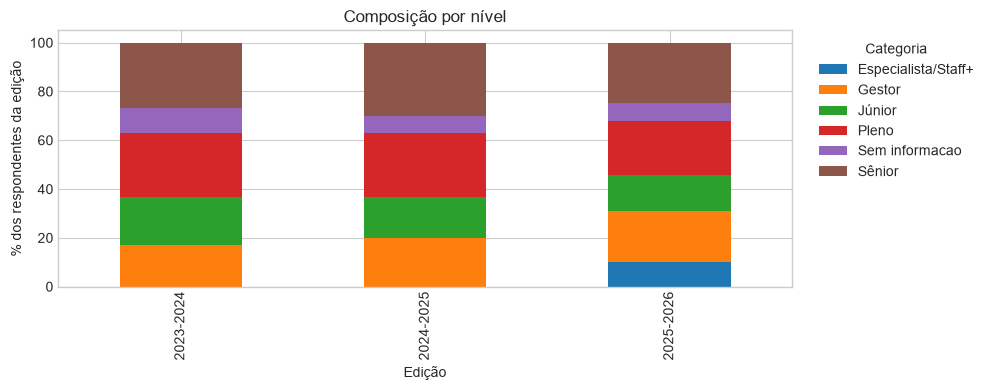

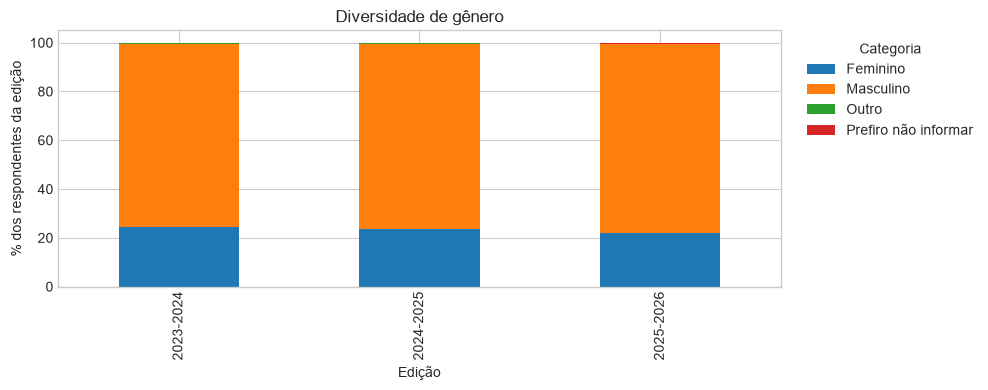

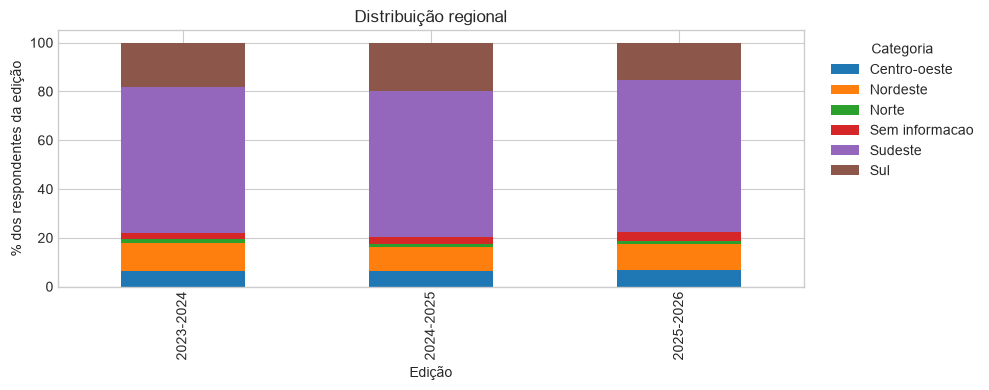

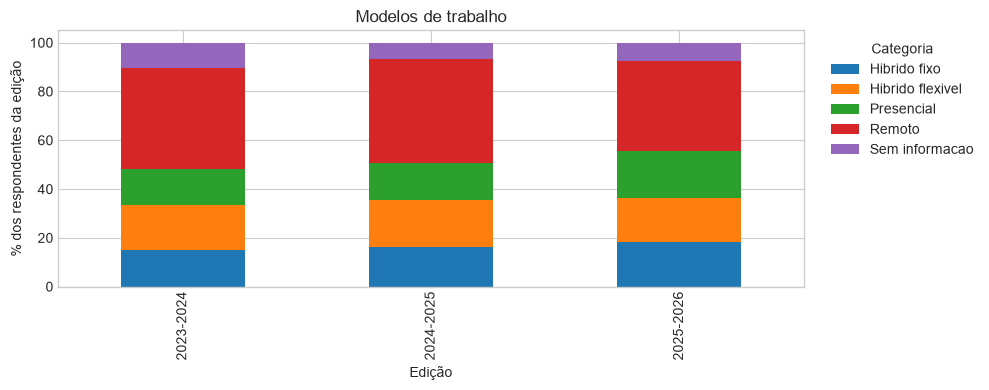

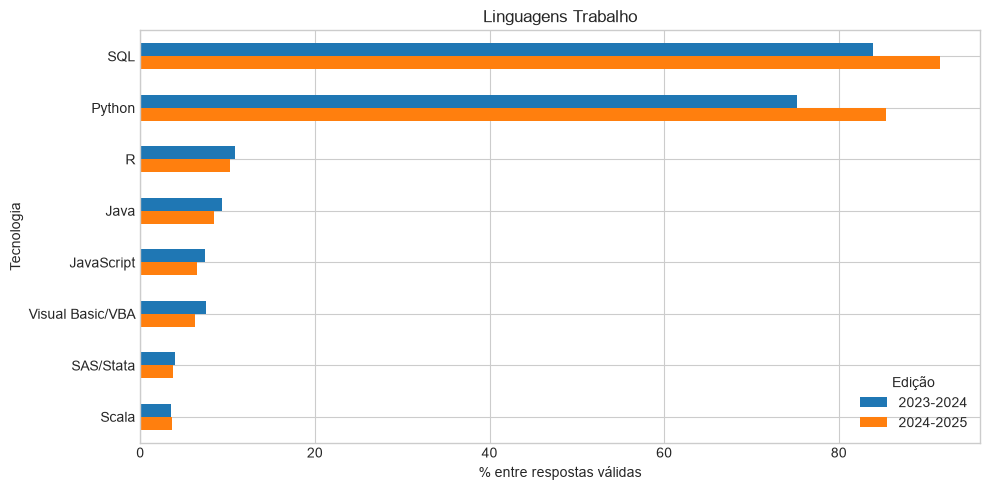

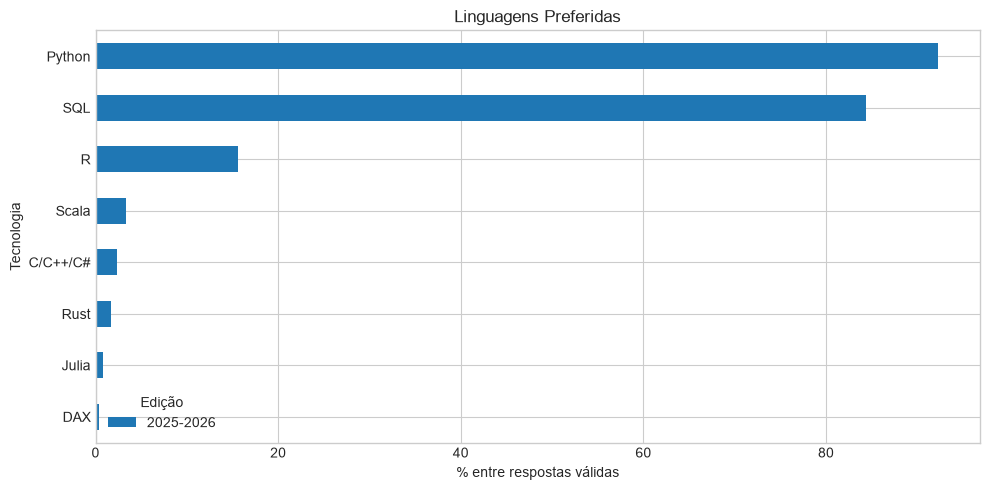

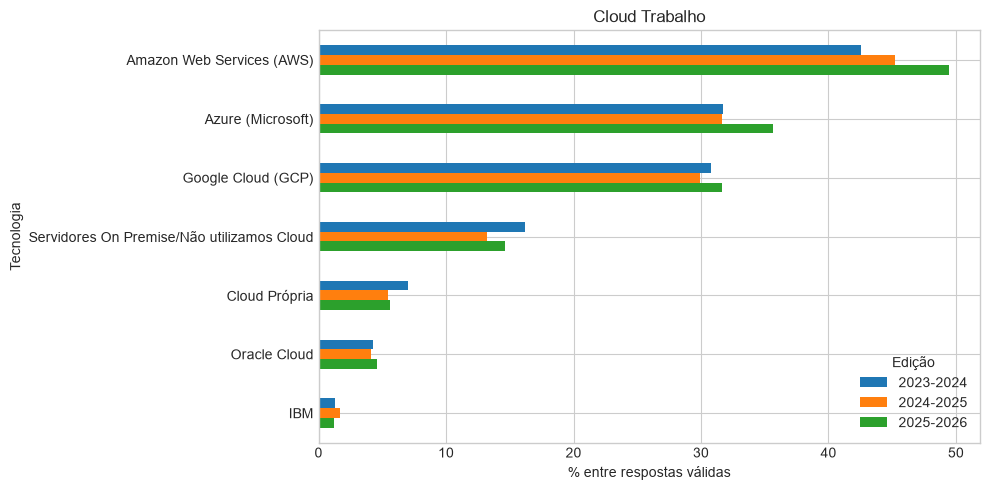

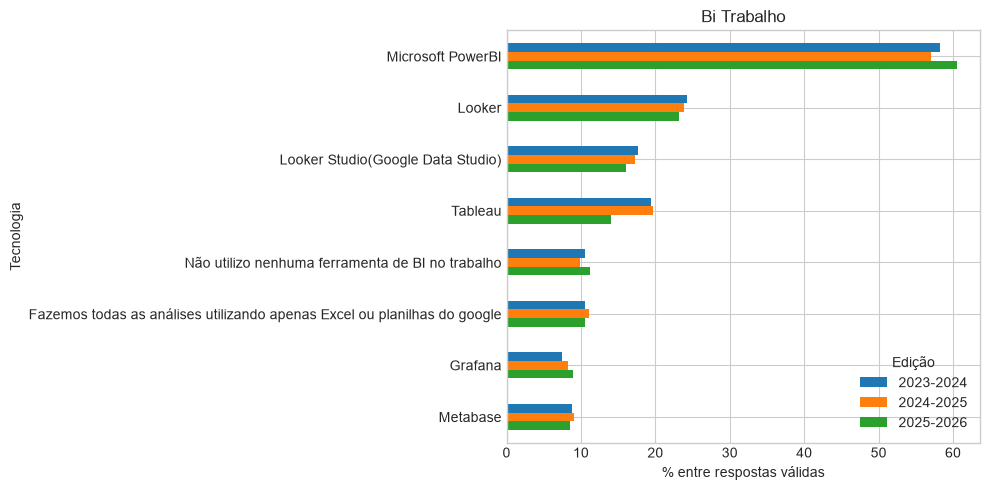

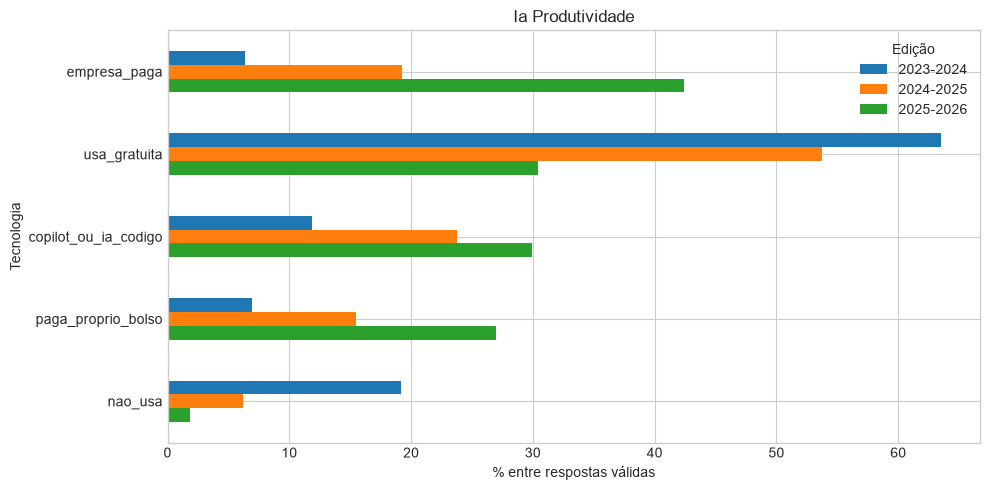

Distribuição por nível e faixa salarial:


,edicao,nivel_comparavel,salario_faixa,count
0,2023-2024,Gestor,Acima de R$ 40.001/mês,35
1,2023-2024,Gestor,Menos de R$ 1.000/mês,5
2,2023-2024,Gestor,de R$ 1.001/mês a R$ 2.000/mês,5
3,2023-2024,Gestor,de R$ 12.001/mês a R$ 16.000/mês,170
4,2023-2024,Gestor,de R$ 16.001/mês a R$ 20.000/mês,163
...,...,...,...,...
131,2025-2026,Senior/Especialista,de R$ 3.001/mês a R$ 4.000/mês,11
132,2025-2026,Senior/Especialista,de R$ 30.001/mês a R$ 40.000/mês,17
133,2025-2026,Senior/Especialista,de R$ 4.001/mês a R$ 6.000/mês,36
134,2025-2026,Senior/Especialista,de R$ 6.001/mês a R$ 8.000/mês,87


In [20]:

# === 7. VISUALIZAÇÃO DOS RESULTADOS ===

import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

# Padronização dos tipos numéricos
perfil["count"] = pd.to_numeric(perfil["count"])
tecnologias["percentual"] = pd.to_numeric(
    tecnologias["percentual"]
)
remuneracao["count"] = pd.to_numeric(
    remuneracao["count"]
)

# === 7.1 PERFIL DOS PROFISSIONAIS ===

graficos_perfil = [
    ("nivel_analitico", "Composição por nível"),
    ("genero", "Diversidade de gênero"),
    ("regiao", "Distribuição regional"),
    ("modelo_trabalho_grupo", "Modelos de trabalho")
]

for campo, titulo in graficos_perfil:

    recorte = perfil.loc[perfil["campo"] == campo]

    if recorte.empty:
        print(f"Sem dados para: {campo}")
        continue

    tabela = recorte.pivot_table(
        index="edicao",
        columns="categoria",
        values="count",
        aggfunc="sum",
        fill_value=0
    ).sort_index()

    # Percentual por edição
    totais = tabela.sum(axis=1)
    tabela_pct = tabela.div(
        totais.where(totais.ne(0)), axis=0
    ) * 100

    ax = tabela_pct.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 4),
        title=titulo
    )

    ax.set_ylabel("% dos respondentes da edição")
    ax.set_xlabel("Edição")
    ax.legend(
        title="Categoria",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()


# === 7.2 TECNOLOGIAS E INTELIGÊNCIA ARTIFICIAL ===

familias = [
    "linguagens_trabalho",
    "linguagens_preferidas",
    "cloud_trabalho",
    "bi_trabalho",
    "ia_produtividade"
]

for familia in familias:

    recorte = tecnologias.loc[
        tecnologias["familia"] == familia
    ].copy()

    # Preferências de linguagens: edição específica
    if familia == "linguagens_preferidas":
        recorte = recorte.loc[
            recorte["edicao"] == "2025-2026"
        ]

    if recorte.empty:
        print(f"Sem dados para: {familia}")
        continue

    # Edição mais recente disponível
    ultima_edicao = sorted(
        recorte["edicao"].dropna().unique()
    )[-1]

    # Top 8 da edição mais recente
    top = (
        recorte.loc[
            recorte["edicao"] == ultima_edicao
        ]
        .sort_values("percentual", ascending=False)
        .head(8)["opcao"]
        .tolist()
    )

    tabela = recorte.loc[
        recorte["opcao"].isin(top)
    ].pivot_table(
        index="opcao",
        columns="edicao",
        values="percentual",
        aggfunc="first"
    )

    tabela = tabela.reindex(top)

    ax = tabela.plot(
        kind="barh",
        figsize=(10, 5),
        title=familia.replace("_", " ").title()
    )

    ax.invert_yaxis()
    ax.set_xlabel("% entre respostas válidas")
    ax.set_ylabel("Tecnologia")
    ax.legend(title="Edição")

    plt.tight_layout()
    plt.show()


# === 7.3 DISTRIBUIÇÃO DE REMUNERAÇÃO ===

tabela_remuneracao = (
    remuneracao.groupby(
        ["edicao", "nivel_comparavel", "salario_faixa"],
        dropna=False,
        as_index=False
    )["count"]
    .sum()
    .sort_values(
        ["edicao", "nivel_comparavel", "salario_faixa"]
    )
)

print("Distribuição por nível e faixa salarial:")
display(tabela_remuneracao)


In [21]:
# === VALIDAÇÃO DAS ANÁLISES ===

datasets = {
    "Perfil": perfil,
    "Tecnologias": tecnologias,
    "Remuneração": remuneracao,
    "Qualidade IA": qualidade_ia
}

for nome, df in datasets.items():
    print(
        f"{nome}: {len(df)} registros | "
        f"{df.shape[1]} colunas"
    )

Perfil: 242 registros | 4 colunas
Tecnologias: 159 registros | 6 colunas
Remuneração: 1161 registros | 6 colunas
Qualidade IA: 9 registros | 3 colunas


## 8. Análises estratégicas no Athena
Esta etapa complementa as distribuições da camada Gold com cruzamentos sobre a **Silver**, preservando as dimensões do respondente. As consultas examinam composição de cargos no setor financeiro, remuneração por nível e setor, participação feminina por cargo, modelo de trabalho por senioridade e modalidades declaradas de uso de IA.

**Recortes e limitações**: as porcentagens têm denominadores explícitos dentro de cada consulta; remuneração corresponde a faixas nominais, apenas entre quem informou salário e atende aos critérios definidos; nenhuma comparação prova causalidade ou demanda real por vagas. Os respondentes são uma amostra voluntária e a edição 2025–2026 contém uma categoria adicional de senioridade. A coluna setor_empresa identifica o setor declarado do empregador, não a instituição contratante do desafio.

In [22]:
# === 8.1. CONSULTAS ESTRATÉGICAS (ATHENA) ===
# Reutiliza a função consultar() e os clientes AWS da etapa 6.

if "consultar" not in globals():
    raise RuntimeError("Execute primeiro a etapa 6 para definir consultar().")

# Composição dos cargos: setor financeiro vs. demais setores
cargos_setor = consultar("""
WITH base AS (
    SELECT
        edicao,
        CASE
            WHEN setor_empresa = 'Finanças ou Bancos' THEN 'Financeiro'
            ELSE 'Demais setores'
        END AS recorte_setor,
        COALESCE(cargo_grupo, 'Sem informacao') AS cargo_grupo
    FROM silver_respostas
    WHERE setor_empresa IS NOT NULL
)
SELECT
    edicao, recorte_setor, cargo_grupo,
    COUNT(*) AS respondentes,
    ROUND(100.0 * COUNT(*) /
          SUM(COUNT(*)) OVER (PARTITION BY edicao, recorte_setor), 2
    ) AS percentual_no_setor
FROM base
GROUP BY edicao, recorte_setor, cargo_grupo
ORDER BY edicao, recorte_setor, respondentes DESC
""")

# Distribuição salarial por edição, setor e nível (sem inventar salário exato)
remuneracao_setor = consultar("""
WITH base AS (
    SELECT
        edicao,
        CASE
            WHEN setor_empresa = 'Finanças ou Bancos' THEN 'Financeiro'
            ELSE 'Demais setores'
        END AS recorte_setor,
        nivel_comparavel,
        salario_faixa
    FROM silver_respostas
    WHERE setor_empresa IS NOT NULL
      AND vive_no_brasil = TRUE
      AND salario_faixa IS NOT NULL
      AND situacao_trabalho IS NOT NULL
      AND situacao_trabalho NOT LIKE '%empresa de fora do Brasil%'
      AND nivel_comparavel IS NOT NULL
)
SELECT
    edicao, recorte_setor, nivel_comparavel, salario_faixa,
    COUNT(*) AS respondentes,
    ROUND(100.0 * COUNT(*) /
          SUM(COUNT(*)) OVER (
              PARTITION BY edicao, recorte_setor, nivel_comparavel
          ), 2
    ) AS percentual_no_grupo
FROM base
GROUP BY edicao, recorte_setor, nivel_comparavel, salario_faixa
ORDER BY edicao, recorte_setor, nivel_comparavel, respondentes DESC
""")

# Participação feminina por grupo de cargo, entre gêneros informados
# Denominador exclui 'Prefiro não informar' e ausência de resposta.
diversidade_cargos = consultar("""
SELECT
    edicao,
    cargo_grupo,
    COUNT(*) AS genero_informado,
    SUM(CASE WHEN genero = 'Feminino' THEN 1 ELSE 0 END) AS mulheres,
    ROUND(100.0 * SUM(CASE WHEN genero = 'Feminino' THEN 1 ELSE 0 END)
          / COUNT(*), 2) AS percentual_feminino
FROM silver_respostas
WHERE genero IN ('Feminino', 'Masculino', 'Outro')
  AND cargo_grupo IS NOT NULL
  AND cargo_grupo <> 'Sem informacao'
GROUP BY edicao, cargo_grupo
ORDER BY edicao, genero_informado DESC
""")

# Modelo de trabalho por senioridade, dentro de cada edição
trabalho_senioridade = consultar("""
SELECT
    edicao, nivel_comparavel, modelo_trabalho_grupo,
    COUNT(*) AS respondentes,
    ROUND(100.0 * COUNT(*) /
          SUM(COUNT(*)) OVER (PARTITION BY edicao, nivel_comparavel), 2
    ) AS percentual_no_nivel
FROM silver_respostas
WHERE nivel_comparavel IS NOT NULL
  AND modelo_trabalho_grupo IS NOT NULL
  AND modelo_trabalho_grupo <> 'Sem informacao'
GROUP BY edicao, nivel_comparavel, modelo_trabalho_grupo
ORDER BY edicao, nivel_comparavel, respondentes DESC
""")

# Modalidades de IA declaradas; NÃO mede impacto causal na produtividade
modalidades_ia = consultar("""
SELECT edicao, opcao, selecionaram, denominador, percentual
FROM gold_tecnologias_ia
WHERE familia = 'ia_produtividade'
ORDER BY edicao, percentual DESC
""")

for nome, df in {
    "Cargos por setor": cargos_setor,
    "Remuneração por setor": remuneracao_setor,
    "Diversidade por cargo": diversidade_cargos,
    "Trabalho por nível": trabalho_senioridade,
    "IA declarada": modalidades_ia
}.items():
    print(f"{nome}: {len(df)} linhas")

display(cargos_setor.head(12))
display(remuneracao_setor.head(12))


Cargos por setor: 48 linhas
Remuneração por setor: 242 linhas
Diversidade por cargo: 21 linhas
Trabalho por nível: 48 linhas
IA declarada: 15 linhas


,edicao,recorte_setor,cargo_grupo,respondentes,percentual_no_setor
0,2023-2024,Demais setores,Sem informacao,748,19.55
1,2023-2024,Demais setores,Analise de Dados,720,18.82
2,2023-2024,Demais setores,Outros cargos,708,18.50
3,2023-2024,Demais setores,Engenharia e Arquitetura de Dados,554,14.48
4,2023-2024,Demais setores,Ciencia de Dados,522,13.64
5,2023-2024,Demais setores,Business Intelligence,426,11.13
6,2023-2024,Demais setores,Analytics Engineering,94,2.46
7,2023-2024,Demais setores,Engenharia de ML e IA,54,1.41
8,2023-2024,Financeiro,Analise de Dados,187,20.17
9,2023-2024,Financeiro,Ciencia de Dados,165,17.80


,edicao,recorte_setor,nivel_comparavel,salario_faixa,respondentes,percentual_no_grupo
0,2023-2024,Demais setores,Gestor,de R$ 12.001/mês a R$ 16.000/mês,143,20.11
1,2023-2024,Demais setores,Gestor,de R$ 16.001/mês a R$ 20.000/mês,127,17.86
2,2023-2024,Demais setores,Gestor,de R$ 8.001/mês a R$ 12.000/mês,109,15.33
3,2023-2024,Demais setores,Gestor,de R$ 20.001/mês a R$ 25.000/mês,84,11.81
4,2023-2024,Demais setores,Gestor,de R$ 25.001/mês a R$ 30.000/mês,57,8.02
5,2023-2024,Demais setores,Gestor,de R$ 6.001/mês a R$ 8.000/mês,52,7.31
6,2023-2024,Demais setores,Gestor,de R$ 4.001/mês a R$ 6.000/mês,39,5.49
7,2023-2024,Demais setores,Gestor,Acima de R$ 40.001/mês,29,4.08
8,2023-2024,Demais setores,Gestor,de R$ 30.001/mês a R$ 40.000/mês,29,4.08
9,2023-2024,Demais setores,Gestor,de R$ 3.001/mês a R$ 4.000/mês,19,2.67


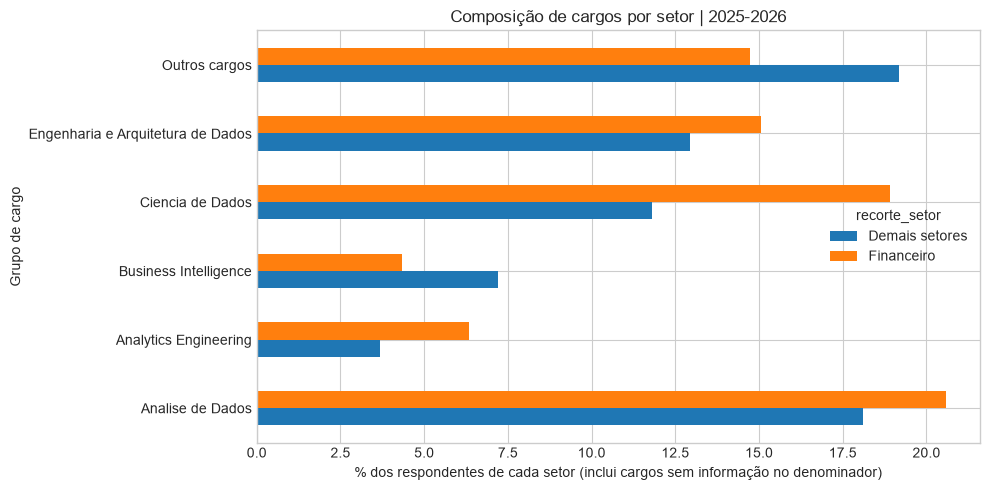

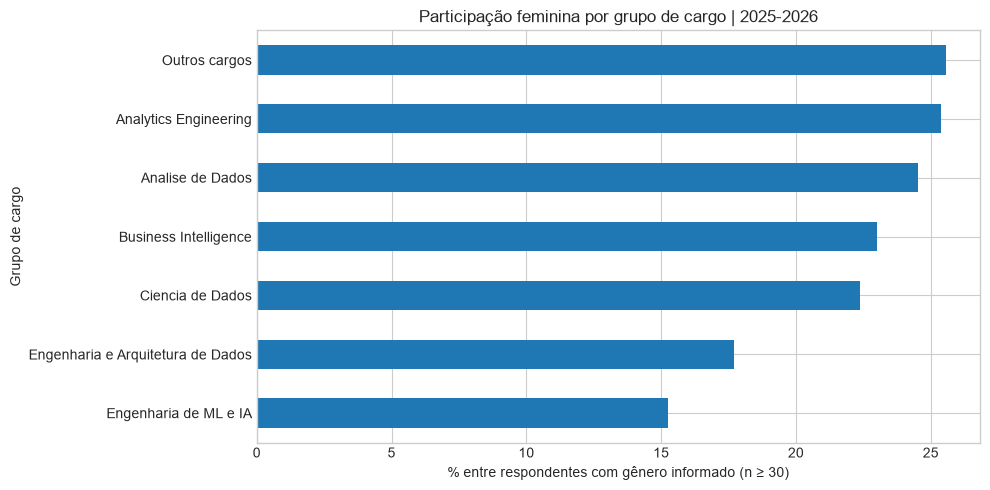

Remuneração: faixa de R$ 12.001/mês ou superior, por nível e setor


,recorte_setor,nivel_comparavel,n,acima_12mil,pct_12mil
0,Demais setores,Gestor,577,411,71.23
1,Demais setores,Júnior,408,4,0.98
2,Demais setores,Pleno,600,49,8.17
3,Demais setores,Senior/Especialista,818,437,53.42
4,Financeiro,Gestor,100,96,96.00
5,Financeiro,Júnior,95,2,2.11
6,Financeiro,Pleno,134,13,9.70
7,Financeiro,Senior/Especialista,248,165,66.53


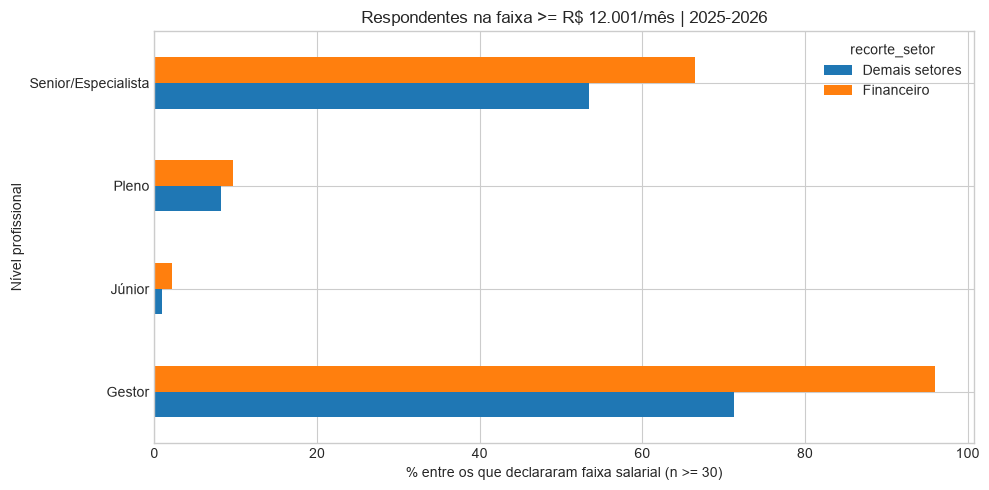

Edição utilizada nos gráficos: 2025-2026


In [23]:
# === 8.2. VISUALIZAÇÕES ESTRATÉGICAS ===
# Gráficos exploratórios calculados exclusivamente sobre os retornos do Athena.

import pandas as pd
import matplotlib.pyplot as plt

edicao_recente = sorted(cargos_setor["edicao"].dropna().unique())[-1]

# Gráfico 1: proporção dos cargos nos dois recortes setoriais
cargos_atuais = cargos_setor.loc[
    (cargos_setor["edicao"] == edicao_recente) &
    (cargos_setor["cargo_grupo"] != "Sem informacao")
].copy()
cargos_atuais["respondentes"] = pd.to_numeric(cargos_atuais["respondentes"])

if not cargos_atuais.empty:
    principais = (cargos_atuais.groupby("cargo_grupo")["respondentes"]
                  .sum().nlargest(6).index)
    tabela = cargos_atuais[cargos_atuais["cargo_grupo"].isin(principais)].pivot_table(
        index="cargo_grupo", columns="recorte_setor",
        values="percentual_no_setor", aggfunc="first"
    )
    tabela.plot.barh(figsize=(10, 5), title=f"Composição de cargos por setor | {edicao_recente}")
    plt.xlabel("% dos respondentes de cada setor (inclui cargos sem informação no denominador)")
    plt.ylabel("Grupo de cargo")
    plt.tight_layout()
    plt.show()

# Gráfico 2: participação feminina por grupos com ao menos 30 respostas de gênero
recorte_genero = diversidade_cargos.loc[
    diversidade_cargos["edicao"].eq(edicao_recente)
].copy()
recorte_genero["genero_informado"] = pd.to_numeric(recorte_genero["genero_informado"])
recorte_genero["percentual_feminino"] = pd.to_numeric(recorte_genero["percentual_feminino"])
recorte_genero = recorte_genero[recorte_genero["genero_informado"] >= 30]

if not recorte_genero.empty:
    recorte_genero = recorte_genero.sort_values("percentual_feminino")
    ax = recorte_genero.plot.barh(
        x="cargo_grupo", y="percentual_feminino", legend=False,
        figsize=(10, 5), title=f"Participação feminina por grupo de cargo | {edicao_recente}"
    )
    ax.set_xlabel("% entre respondentes com gênero informado (n ≥ 30)")
    ax.set_ylabel("Grupo de cargo")
    plt.tight_layout()
    plt.show()

# Gráfico 3: faixas salariais elevadas, sem estimar salários médios
# Percentual de respostas válidas na faixa >= R$ 12.001/mês.
faixas_12mil = {
    "de R$ 12.001/mês a R$ 16.000/mês",
    "de R$ 16.001/mês a R$ 20.000/mês",
    "de R$ 20.001/mês a R$ 25.000/mês",
    "de R$ 25.001/mês a R$ 30.000/mês",
    "de R$ 30.001/mês a R$ 40.000/mês",
    "Acima de R$ 40.001/mês"
}
salario_atual = remuneracao_setor.loc[
    remuneracao_setor["edicao"].eq(edicao_recente)
].copy()
salario_atual["respondentes"] = pd.to_numeric(salario_atual["respondentes"])
salario_atual["faixa_12mil_ou_mais"] = salario_atual["salario_faixa"].isin(faixas_12mil)

if not salario_atual.empty:
    salario_atual["respondentes_12mil"] = salario_atual["respondentes"].where(
        salario_atual["faixa_12mil_ou_mais"], 0
    )
    pct_salario = salario_atual.groupby(
        ["recorte_setor", "nivel_comparavel"], as_index=False
    ).agg(n=("respondentes", "sum"), acima_12mil=("respondentes_12mil", "sum"))
    pct_salario["pct_12mil"] = (
        100 * pct_salario["acima_12mil"] / pct_salario["n"]
    ).round(2)
    print("Remuneração: faixa de R$ 12.001/mês ou superior, por nível e setor")
    display(pct_salario.sort_values(["recorte_setor", "nivel_comparavel"]))

    grafico_salario = pct_salario.loc[pct_salario["n"] >= 30]
    if not grafico_salario.empty:
        tabela_salario = grafico_salario.pivot_table(
            index="nivel_comparavel", columns="recorte_setor",
            values="pct_12mil", aggfunc="first"
        )
        ax = tabela_salario.plot.barh(
            figsize=(10, 5),
            title=f"Respondentes na faixa >= R$ 12.001/mês | {edicao_recente}"
        )
        ax.set_xlabel("% entre os que declararam faixa salarial (n >= 30)")
        ax.set_ylabel("Nível profissional")
        plt.tight_layout()
        plt.show()

# Amostras pequenas devem ser destacadas e não usadas para generalizações.
print("Edição utilizada nos gráficos:", edicao_recente)


## 9. Insights e recomendações estratégicas
Nesta etapa, os resultados das consultas são convertidos em sete respostas para o problema de negócio da FIAP: apoiar uma instituição financeira em decisões de contratação, capacitação e investimento em Dados e Inteligência Artificial.

**Fonte dos indicadores**: State of Data Brazil (Data Hackers/Bain), edições 2023–2024, 2024–2025 e 2025–2026, após tratamento por AWS Glue/PySpark e consulta via Athena. O projeto abrange 14.005 respostas brutas e 14.002 após a remoção de três duplicações exatas.

**Critérios de interpretação**: pesquisas voluntárias não equivalem a uma amostra representativa de vagas ou empresas brasileiras. O uso declarado de ferramentas não mede demanda de contratação; faixas salariais não permitem calcular salários médios exatos; associações não demonstram causalidade. Percentuais de opções de múltipla escolha podem somar mais de 100%. Sempre que possível, apresentamos os denominadores e destacamos amostras pequenas.

A primeira célula acrescenta dois cruzamentos necessários para fechar as perguntas do enunciado: **região** × **senioridade** e **adoção declarada de IA entre respostas válidas**. As demais respostas serão calculadas dinamicamente a partir dos DataFrames das etapas 6 e 8, sem fabricar números.

In [24]:
# === 9.1. CONSULTAS COMPLEMENTARES NO ATHENA ===
# Execute após as etapas 6 e 8.1 (função consultar e DataFrames disponíveis).

necessarios = [
    "consultar", "perfil", "tecnologias", "qualidade_ia",
    "cargos_setor", "remuneracao_setor", "diversidade_cargos",
    "trabalho_senioridade", "modalidades_ia"
]
ausentes = [nome for nome in necessarios if nome not in globals()]
if ausentes:
    raise RuntimeError("Execute as etapas 6 e 8.1 antes da 9.1. Ausentes: " + ", ".join(ausentes))

# Distribuição de níveis por região, considerando apenas regiões identificadas.
regional_senioridade = consultar("""
SELECT
    edicao,
    regiao,
    nivel_comparavel,
    COUNT(*) AS respondentes,
    ROUND(100.0 * COUNT(*) /
          SUM(COUNT(*)) OVER (PARTITION BY edicao, regiao), 2
    ) AS percentual_na_regiao
FROM silver_respostas
WHERE regiao IS NOT NULL
  AND TRIM(regiao) <> ''
  AND regiao <> 'Sem informacao'
  AND nivel_comparavel IS NOT NULL
  AND TRIM(nivel_comparavel) <> ''
GROUP BY edicao, regiao, nivel_comparavel
ORDER BY edicao, regiao, respondentes DESC
""")

# Para não contar uma pessoa mais de uma vez em perguntas de múltipla escolha,
# consolidamos as opções no nível (edição, respondente).
# 'Não uso' é uma opção exclusiva; consideramos somente respostas válidas.
adocao_ia = consultar("""
WITH respostas AS (
    SELECT
        edicao,
        respondente_id,
        MAX(CASE WHEN opcao = 'nao_usa' AND selecionado = 1
                 THEN 1 ELSE 0 END) AS nao_usa,
        MAX(CASE WHEN opcao <> 'nao_usa' AND selecionado = 1
                 THEN 1 ELSE 0 END) AS usa_ia
    FROM silver_opcoes
    WHERE familia = 'ia_produtividade'
      AND status_resposta = 'valida'
    GROUP BY edicao, respondente_id
)
SELECT
    edicao,
    COUNT(*) AS respostas_validas,
    SUM(usa_ia) AS declararam_uso,
    SUM(nao_usa) AS declararam_nao_uso,
    ROUND(100.0 * SUM(usa_ia) / COUNT(*), 2) AS percentual_entre_validas
FROM respostas
GROUP BY edicao
ORDER BY edicao
""")

print("Cruzamentos complementares concluídos.")
display(adocao_ia)
display(regional_senioridade.head(12))


Cruzamentos complementares concluídos.


,edicao,respostas_validas,declararam_uso,declararam_nao_uso,percentual_entre_validas
0,2023-2024,3746,3028,718,80.83
1,2024-2025,3604,3381,223,93.81
2,2025-2026,2100,2061,39,98.14


,edicao,regiao,nivel_comparavel,respondentes,percentual_na_regiao
0,2023-2024,Centro-oeste,Senior/Especialista,91,29.93
1,2023-2024,Centro-oeste,Pleno,80,26.32
2,2023-2024,Centro-oeste,Júnior,76,25.00
3,2023-2024,Centro-oeste,Gestor,57,18.75
4,2023-2024,Nordeste,Pleno,168,33.53
5,2023-2024,Nordeste,Júnior,141,28.14
6,2023-2024,Nordeste,Senior/Especialista,121,24.15
7,2023-2024,Nordeste,Gestor,71,14.17
8,2023-2024,Norte,Pleno,27,39.13
9,2023-2024,Norte,Júnior,21,30.43


In [25]:
# === 9.2. RESPOSTAS ÀS SETE PERGUNTAS DO TECH CHALLENGE ===
# Evidências calculadas a partir dos resultados do Athena; sem valores simulados.
import pandas as pd
from IPython.display import display, Markdown

ult = sorted(perfil["edicao"].dropna().unique())[-1]

def inteiro(v):
    return f"{int(v):,}".replace(",", ".")

def pct(v):
    return f"{float(v):.2f}%".replace(".", ",")

def maior_grupo(df, coluna_valor, filtro=None):
    rec = df.copy() if filtro is None else df.loc[filtro].copy()
    rec[coluna_valor] = pd.to_numeric(rec[coluna_valor], errors="coerce")
    return rec.sort_values(coluna_valor, ascending=False).iloc[0] if not rec.empty else None

perguntas = []
def adicionar(numero, pergunta, evidencia, interpretacao, recomendacao, ressalva):
    perguntas.append({
        "Nº": numero, "Pergunta": pergunta, "Evidência": evidencia,
        "Interpretação": interpretacao, "Recomendação": recomendacao,
        "Limitação": ressalva
    })

# 1. Estrutura do mercado: recorte com setor informado e cargos identificados.
cs = cargos_setor.loc[
    cargos_setor["edicao"].eq(ult) &
    cargos_setor["recorte_setor"].eq("Financeiro")
].copy()
cs["respondentes"] = pd.to_numeric(cs["respondentes"])
total_setor = int(cs["respondentes"].sum())
cs_validos = cs.loc[~cs["cargo_grupo"].isin(["Sem informacao", "Sem informação"])].copy()
if cs_validos.empty:
    raise ValueError("Sem cargos identificados no setor financeiro para a edição mais recente.")
top_cargo = cs_validos.sort_values("respondentes", ascending=False).iloc[0]
adicionar(
    1, "Como está estruturado o mercado brasileiro de Dados?",
    f"Na edição {ult}, entre {inteiro(total_setor)} respondentes com setor financeiro identificado, "
    f"o maior grupo de cargo informado foi '{top_cargo['cargo_grupo']}', com "
    f"{inteiro(top_cargo['respondentes'])} respostas ({pct(top_cargo['percentual_no_setor'])} do setor, inclusive cargos sem informação no denominador).",
    "O levantamento contém perfis profissionais distintos; o peso de cada função varia por recorte setorial.",
    "Mapear vagas e competências da instituição por trilhas de Análise, Engenharia, Ciência de Dados e BI antes de definir metas de contratação.",
    "Distribuição de respondentes não equivale à estrutura de empregos ou à quantidade de vagas no Brasil."
)

# 2. Perfis valorizados: comparar remuneração por faixas, não salário exato.
faixas_altas = {
    "de R$ 12.001/mês a R$ 16.000/mês", "de R$ 16.001/mês a R$ 20.000/mês",
    "de R$ 20.001/mês a R$ 25.000/mês", "de R$ 25.001/mês a R$ 30.000/mês",
    "de R$ 30.001/mês a R$ 40.000/mês", "Acima de R$ 40.001/mês"
}
sal = remuneracao_setor.loc[remuneracao_setor["edicao"].eq(ult)].copy()
sal["respondentes"] = pd.to_numeric(sal["respondentes"])
sal["altas"] = sal["respondentes"].where(sal["salario_faixa"].isin(faixas_altas), 0)
sal = sal.groupby(["recorte_setor", "nivel_comparavel"], as_index=False).agg(
    amostra=("respondentes", "sum"), altas=("altas", "sum")
)
sal["percentual"] = 100 * sal["altas"] / sal["amostra"]
sal_gest = sal[sal["nivel_comparavel"].eq("Gestor")]
comparativo = sal_gest.set_index("recorte_setor")
if {"Financeiro", "Demais setores"}.issubset(comparativo.index):
    f, d = comparativo.loc["Financeiro"], comparativo.loc["Demais setores"]
    evidencia_sal = (f"Gestores na faixa >= R$ 12.001/mês ({ult}): "
        f"{pct(f['percentual'])} no financeiro ({inteiro(f['altas'])}/{inteiro(f['amostra'])}) "
        f"e {pct(d['percentual'])} nos demais setores ({inteiro(d['altas'])}/{inteiro(d['amostra'])}).")
else:
    evidencia_sal = "A distribuição de faixas salariais por nível foi calculada, mas falta comparador setorial para gestores."
adicionar(
    2, "Quais perfis profissionais são mais valorizados?",
    evidencia_sal,
    "Há diferenças de remuneração declarada entre níveis e setores; isso sinaliza posicionamento salarial, não demanda ou produtividade.",
    "Comparar faixas de remuneração por senioridade em pesquisas adicionais e construir uma proposta de carreira e remuneração transparente.",
    "Faixas nominais, amostra voluntária e filtros de residência/trabalho; não é possível estimar salários médios exatos."
)

# 3. Diversidade: grupos com n >= 30, sobre o gênero informado.
gen = diversidade_cargos.loc[diversidade_cargos["edicao"].eq(ult)].copy()
for col in ["genero_informado", "mulheres", "percentual_feminino"]:
    gen[col] = pd.to_numeric(gen[col], errors="coerce")
gen = gen.loc[gen["genero_informado"].ge(30)]
if not gen.empty:
    baixo = gen.sort_values("percentual_feminino").iloc[0]
    alto = gen.sort_values("percentual_feminino").iloc[-1]
    evidencia_gen = (
        f"Em {ult}, dentre cargos com pelo menos 30 respostas de gênero, a participação feminina "
        f"variou de {pct(baixo['percentual_feminino'])} em '{baixo['cargo_grupo']}' "
        f"(n={inteiro(baixo['genero_informado'])}) a {pct(alto['percentual_feminino'])} "
        f"em '{alto['cargo_grupo']}' (n={inteiro(alto['genero_informado'])})."
    )
else:
    evidencia_gen = "Não há amostra suficiente por cargo (n >= 30) para comparação nesta edição."
adicionar(
    3, "Qual é o cenário de diversidade de gênero?",
    evidencia_gen,
    "A composição de gênero difere entre funções da amostra, e a comparação precisa respeitar respostas ausentes.",
    "Monitorar diversidade por função e senioridade nos processos seletivos, revisar critérios de promoção e ampliar formação de talentos sub-representados.",
    "Percentuais calculados apenas entre respostas com gênero informado; pesquisa não representativa."
)

# 4. Tecnologias: utilização no trabalho versus preferência, conforme edição.
tech_ult = tecnologias.loc[tecnologias["edicao"].eq(ult)].copy()
tech_ult["percentual"] = pd.to_numeric(tech_ult["percentual"], errors="coerce")
tec_textos = []
for fam, rotulo in [("cloud_trabalho", "Cloud"), ("bi_trabalho", "BI"),
                    ("linguagens_preferidas", "linguagens preferidas")]:
    bloco = tech_ult.loc[tech_ult["familia"].eq(fam)].sort_values("percentual", ascending=False)
    if not bloco.empty:
        item = bloco.iloc[0]
        tec_textos.append(f"{rotulo}: '{item['opcao']}' ({pct(item['percentual'])} entre respostas válidas)")
evidencia_tec = f"Em {ult}, maior opção informada por família: " + "; ".join(tec_textos) + "."
adicionar(
    4, "Quais tecnologias apresentam maior adoção?",
    evidencia_tec,
    "Adoção e preferência indicam familiaridade tecnológica autorreferida, não volume de vagas ou exigências de empresas.",
    "Priorizar trilhas técnicas conforme o stack institucional e testar aderência das ferramentas de Cloud, BI e linguagens em projetos-piloto.",
    "Em 2025–2026 há linguagens preferidas, enquanto nas edições anteriores há linguagens utilizadas no trabalho; não comparar como mesma série."
)

# 5. IA: denominadores separados (respostas válidas vs todos os respondentes).
aia = adocao_ia.loc[adocao_ia["edicao"].eq(ult)].iloc[0]
qa = qualidade_ia.loc[qualidade_ia["edicao"].eq(ult)].copy()
qa["count"] = pd.to_numeric(qa["count"])
respondentes_ia_total = int(qa["count"].sum())
validas_audit = int(qa.loc[qa["status_resposta"].eq("valida"), "count"].sum())
validas_consulta = int(aia["respostas_validas"])
if validas_audit != validas_consulta:
    raise AssertionError("Divergência nas respostas válidas de IA entre silver_opcoes e gold_qualidade_ia.")
evidencia_ia = (
    f"Em {ult}, {inteiro(aia['declararam_uso'])} de {inteiro(validas_consulta)} "
    f"respostas válidas declararam algum uso de IA para produtividade "
    f"({pct(aia['percentual_entre_validas'])}). "
    f"As respostas válidas representam {pct(100 * validas_consulta / respondentes_ia_total)} "
    f"dos {inteiro(respondentes_ia_total)} participantes da edição."
)
adicionar(
    5, "Qual é o índice de adoção de IA e seu impacto?",
    evidencia_ia,
    "Há uso declarado de ferramentas de IA, mas esta pesquisa não estabelece ganhos de produtividade, qualidade ou retorno financeiro atribuíveis a elas.",
    "Executar piloto de IA com governança e métricas antes/depois (tempo, qualidade, custo e segurança), acompanhado de grupo comparável quando viável.",
    "Taxa condicionada a respostas válidas; não extrapolar aos não respondentes nem interpretar como efeito causal."
)

# 6. Diferenças de região, nível e modelo de trabalho.
reg = regional_senioridade.loc[regional_senioridade["edicao"].eq(ult)].copy()
reg["respondentes"] = pd.to_numeric(reg["respondentes"])
reg_n = reg.groupby("regiao")["respondentes"].sum()
reg = reg.assign(n_regiao=reg["regiao"].map(reg_n))
reg = reg.loc[reg["n_regiao"].ge(30)]
reg_sr = reg.loc[reg["nivel_comparavel"].eq("Senior/Especialista")].copy()
reg_sr["pct_sr"] = 100 * reg_sr["respondentes"] / reg_sr["n_regiao"]
if len(reg_sr) >= 2:
    menor = reg_sr.sort_values("pct_sr").iloc[0]
    maior = reg_sr.sort_values("pct_sr").iloc[-1]
    regioes_texto = (f"Parcela de Senior/Especialista por região: "
        f"{pct(menor['pct_sr'])} em {menor['regiao']} (n={inteiro(menor['n_regiao'])}) "
        f"versus {pct(maior['pct_sr'])} em {maior['regiao']} "
        f"(n={inteiro(maior['n_regiao'])}).")
else:
    regioes_texto = "Não há regiões suficientes com n >= 30 para comparação de senioridade."
trab = trabalho_senioridade.loc[trabalho_senioridade["edicao"].eq(ult)].copy()
trab["respondentes"] = pd.to_numeric(trab["respondentes"])
trab["percentual_no_nivel"] = pd.to_numeric(trab["percentual_no_nivel"])
top_modelos = (trab.sort_values("respondentes", ascending=False)
    .drop_duplicates("nivel_comparavel")
    .sort_values("nivel_comparavel"))
modelos_texto = "; ".join(
    f"{r.nivel_comparavel}: {r.modelo_trabalho_grupo} ({pct(r.percentual_no_nivel)})"
    for r in top_modelos.itertuples(index=False)
)
adicionar(
    6, "Há diferenças regionais, de senioridade e de modelo de trabalho?",
    f"Em {ult}, {regioes_texto} Modelos mais frequentes por nível: {modelos_texto}.",
    "O perfil dos respondentes e suas modalidades de trabalho variam por região e senioridade.",
    "Planejar atração de talentos por praça e flexibilidade de trabalho, validando com capacidade de contratação e políticas internas.",
    "Regiões ausentes foram excluídas; comparação regional só usa n >= 30 e não ajusta diferenças de composição da amostra."
)

# 7. Síntese do cenário competitivo: decisão, não novo dado.
adicionar(
    7, "Quais oportunidades e desafios existem para investir em Dados e IA?",
    "Síntese das evidências anteriores: diferentes distribuições de cargos e salários, diversidade desigual por função, tecnologias declaradas e uso de IA entre respostas válidas.",
    "Oportunidades: capacitação por função, recrutamento mais focalizado e testes controlados de IA. Desafios: competitividade, inclusão, governança e viés de amostragem.",
    "Priorizar: (1) trilhas e matriz de competências; (2) revisão de recrutamento, remuneração e diversidade; (3) pilotos de IA com métricas de valor e risco.",
    "Essas ações são recomendações derivadas da análise, não impactos mensurados pela pesquisa."
)

respostas_tc = pd.DataFrame(perguntas).sort_values("Nº")
assert len(respostas_tc) == 7

for item in respostas_tc.to_dict("records"):
    display(Markdown(
        f"### {item['Nº']}. {item['Pergunta']}\n\n"
        f"**Evidência:** {item['Evidência']}\n\n"
        f"**Interpretação:** {item['Interpretação']}\n\n"
        f"**Recomendação:** {item['Recomendação']}\n\n"
        f"*Limitação: {item['Limitação']}*"
    ))


### 1. Como está estruturado o mercado brasileiro de Dados?

**Evidência:** Na edição 2025-2026, entre 598 respondentes com setor financeiro identificado, o maior grupo de cargo informado foi 'Analise de Dados', com 123 respostas (20,57% do setor, inclusive cargos sem informação no denominador).

**Interpretação:** O levantamento contém perfis profissionais distintos; o peso de cada função varia por recorte setorial.

**Recomendação:** Mapear vagas e competências da instituição por trilhas de Análise, Engenharia, Ciência de Dados e BI antes de definir metas de contratação.

*Limitação: Distribuição de respondentes não equivale à estrutura de empregos ou à quantidade de vagas no Brasil.*

### 2. Quais perfis profissionais são mais valorizados?

**Evidência:** Gestores na faixa >= R$ 12.001/mês (2025-2026): 96,00% no financeiro (96/100) e 71,23% nos demais setores (411/577).

**Interpretação:** Há diferenças de remuneração declarada entre níveis e setores; isso sinaliza posicionamento salarial, não demanda ou produtividade.

**Recomendação:** Comparar faixas de remuneração por senioridade em pesquisas adicionais e construir uma proposta de carreira e remuneração transparente.

*Limitação: Faixas nominais, amostra voluntária e filtros de residência/trabalho; não é possível estimar salários médios exatos.*

### 3. Qual é o cenário de diversidade de gênero?

**Evidência:** Em 2025-2026, dentre cargos com pelo menos 30 respostas de gênero, a participação feminina variou de 15,24% em 'Engenharia de ML e IA' (n=105) a 25,55% em 'Outros cargos' (n=591).

**Interpretação:** A composição de gênero difere entre funções da amostra, e a comparação precisa respeitar respostas ausentes.

**Recomendação:** Monitorar diversidade por função e senioridade nos processos seletivos, revisar critérios de promoção e ampliar formação de talentos sub-representados.

*Limitação: Percentuais calculados apenas entre respostas com gênero informado; pesquisa não representativa.*

### 4. Quais tecnologias apresentam maior adoção?

**Evidência:** Em 2025-2026, maior opção informada por família: Cloud: 'Amazon Web Services (AWS)' (49,41% entre respostas válidas); BI: 'Microsoft PowerBI' (60,59% entre respostas válidas); linguagens preferidas: 'Python' (92,25% entre respostas válidas).

**Interpretação:** Adoção e preferência indicam familiaridade tecnológica autorreferida, não volume de vagas ou exigências de empresas.

**Recomendação:** Priorizar trilhas técnicas conforme o stack institucional e testar aderência das ferramentas de Cloud, BI e linguagens em projetos-piloto.

*Limitação: Em 2025–2026 há linguagens preferidas, enquanto nas edições anteriores há linguagens utilizadas no trabalho; não comparar como mesma série.*

### 5. Qual é o índice de adoção de IA e seu impacto?

**Evidência:** Em 2025-2026, 2.061 de 2.100 respostas válidas declararam algum uso de IA para produtividade (98,14%). As respostas válidas representam 60,10% dos 3.494 participantes da edição.

**Interpretação:** Há uso declarado de ferramentas de IA, mas esta pesquisa não estabelece ganhos de produtividade, qualidade ou retorno financeiro atribuíveis a elas.

**Recomendação:** Executar piloto de IA com governança e métricas antes/depois (tempo, qualidade, custo e segurança), acompanhado de grupo comparável quando viável.

*Limitação: Taxa condicionada a respostas válidas; não extrapolar aos não respondentes nem interpretar como efeito causal.*

### 6. Há diferenças regionais, de senioridade e de modelo de trabalho?

**Evidência:** Em 2025-2026, Parcela de Senior/Especialista por região: 31,31% em Nordeste (n=329) versus 41,67% em Norte (n=36). Modelos mais frequentes por nível: Gestor: Remoto (31,91%); Júnior: Presencial (36,68%); Pleno: Remoto (39,87%); Senior/Especialista: Remoto (50,21%).

**Interpretação:** O perfil dos respondentes e suas modalidades de trabalho variam por região e senioridade.

**Recomendação:** Planejar atração de talentos por praça e flexibilidade de trabalho, validando com capacidade de contratação e políticas internas.

*Limitação: Regiões ausentes foram excluídas; comparação regional só usa n >= 30 e não ajusta diferenças de composição da amostra.*

### 7. Quais oportunidades e desafios existem para investir em Dados e IA?

**Evidência:** Síntese das evidências anteriores: diferentes distribuições de cargos e salários, diversidade desigual por função, tecnologias declaradas e uso de IA entre respostas válidas.

**Interpretação:** Oportunidades: capacitação por função, recrutamento mais focalizado e testes controlados de IA. Desafios: competitividade, inclusão, governança e viés de amostragem.

**Recomendação:** Priorizar: (1) trilhas e matriz de competências; (2) revisão de recrutamento, remuneração e diversidade; (3) pilotos de IA com métricas de valor e risco.

*Limitação: Essas ações são recomendações derivadas da análise, não impactos mensurados pela pesquisa.*

In [26]:
# === 9.3. REGISTRO DOS RESULTADOS PARA A APRESENTAÇÃO ===
# Exportação local dos insights, sem necessidade de executar o ETL novamente.
from pathlib import Path

PASTA_ENTREGA = RAIZ_PROJETO / "results"
PASTA_ENTREGA.mkdir(parents=True, exist_ok=True)

csv_saida = PASTA_ENTREGA / "etapa9_insights_e_recomendacoes.csv"
md_saida = PASTA_ENTREGA / "etapa9_respostas_executivas.md"

respostas_tc.to_csv(csv_saida, sep=";", index=False, encoding="utf-8-sig")

partes = [
    "# Tech Challenge Fase 3: respostas executivas às sete perguntas",
    f"Fonte: State of Data Brazil, edições 2023–2024 a {ult}.",
    "Indicadores processados no AWS Glue e consultados no Amazon Athena.",
    "## Nota metodológica",
    "Dados voluntários e autorreferidos. Os recortes e denominadores são especificados nos insights. "
    "Associação não é causalidade; adoção de IA não mede impacto na produtividade."
]
for item in respostas_tc.to_dict("records"):
    partes += [
        f"## {item['Nº']}. {item['Pergunta']}",
        f"**Evidência:** {item['Evidência']}",
        f"**Interpretação:** {item['Interpretação']}",
        f"**Recomendação:** {item['Recomendação']}",
        f"**Limitação:** {item['Limitação']}"
    ]
partes.extend([
    "## Prioridades propostas para a instituição financeira",
    "1. Recrutamento e carreira: validar perfis e faixas de remuneração com dados internos e pesquisas de vagas.",
    "2. Capacitação: alinhar habilidades em Dados, Cloud, BI e IA ao stack e às necessidades da instituição.",
    "3. IA responsável: conduzir piloto de valor mensurável e avaliação de segurança, qualidade e governança.",
    "## Referências e rastreabilidade",
    "- Data Hackers / Bain — State of Data Brazil: https://www.kaggle.com/datahackers/datasets",
    "- Tabelas: silver_respostas, silver_opcoes, gold_perfil, gold_tecnologias_ia, gold_qualidade_ia.",
    "- Consultas das etapas 6, 8.1 e 9.1 deste notebook."
])
md_saida.write_text("\n\n".join(partes) + "\n", encoding="utf-8")

print("Etapa 9 concluída: 7 perguntas com evidências e recomendações.")
print("CSV:", csv_saida.resolve())
print("Texto executivo:", md_saida.resolve())
display(respostas_tc[["Nº", "Pergunta", "Recomendação"]])


Etapa 9 concluída: 7 perguntas com evidências e recomendações.
CSV: C:\Users\conta\OneDrive\Documentos\Formações\Pós Tech - Data Analytics\3º Fase - Big Data to Analytics\Tech Challenge - Fase 3\Tech_Challenge_Fase3_Etapa1\entregaveis\etapa9_insights_e_recomendacoes.csv
Texto executivo: C:\Users\conta\OneDrive\Documentos\Formações\Pós Tech - Data Analytics\3º Fase - Big Data to Analytics\Tech Challenge - Fase 3\Tech_Challenge_Fase3_Etapa1\entregaveis\etapa9_respostas_executivas.md


,Nº,Pergunta,Recomendação
0,1,Como está estruturado o mercado brasileiro de ...,Mapear vagas e competências da instituição por...
1,2,Quais perfis profissionais são mais valorizados?,Comparar faixas de remuneração por senioridade...
2,3,Qual é o cenário de diversidade de gênero?,Monitorar diversidade por função e senioridade...
3,4,Quais tecnologias apresentam maior adoção?,Priorizar trilhas técnicas conforme o stack in...
4,5,Qual é o índice de adoção de IA e seu impacto?,Executar piloto de IA com governança e métrica...
5,6,"Há diferenças regionais, de senioridade e de m...",Planejar atração de talentos por praça e flexi...
6,7,Quais oportunidades e desafios existem para in...,Priorizar: (1) trilhas e matriz de competência...


## 10. Discussão e conclusões
Os resultados apoiam o planejamento de contratação, capacitação e investimento em uma instituição financeira. As sete respostas executivas da seção 9 apresentam indicadores, interpretações e recomendações.

Na edição 2025–2026, a parcela nas faixas de R$ 12.001/mês ou superiores foi de **66,53% entre Sênior/Especialista no setor financeiro (165/248)**, contra **53,42% nos demais setores (437/818)**. Entre gestores, foram 96,00% (96/100) e 71,23% (411/577), respectivamente. Esses recortes misturam cargos e vínculos; descrevem diferenças na amostra, sem isolar um efeito do setor sobre a remuneração.

A adoção declarada de IA entre respostas válidas passou de **80,83% em 2023–2024** para **93,81% em 2024–2025** e **98,14% em 2025–2026**, diferença de 17,31 pontos percentuais entre os extremos. Em 2025–2026, as 2.100 respostas válidas correspondem a 60,10% das 3.494 respostas da edição. As mudanças nos exemplos de ferramentas e na composição da amostra limitam a comparação temporal. Uso declarado não comprova impacto causal na produtividade.

Na análise de gênero, **Outros cargos** é uma categoria agregada e não uma carreira específica. Comparações entre funções identificadas orientam o detalhamento das ações de diversidade. Na análise regional, o Norte reúne apenas **36 respostas com região e nível informados**. Seu percentual deve ser lido como descritivo, sem orientar isoladamente uma estratégia de recrutamento.

As prioridades propostas são mapear competências por função, usar referências salariais comparáveis e testar aplicações de IA com métricas de qualidade, tempo, custo e segurança.

## 11. Entregáveis do Tech Challenge
- Notebook com códigos, consultas e saídas salvas.
- Diagrama editável em Draw.io, com fontes, serviços AWS e fluxo de dados.
- Apresentação executiva em PowerPoint e PDF, com gráficos, limitações, recomendações e arquitetura incorporada.

## Referências
- State of Data Brazil, Data Hackers e Bain & Company: https://www.kaggle.com/datahackers/datasets
- Mapeamento de referência: https://github.com/data-hackers-br/state-of-data-brazil — commit e8620de865958f99b71108c02e6e6022388a6b00.
- Dados e mapeamentos derivados sob CC BY-NC-SA 4.0: https://creativecommons.org/licenses/by-nc-sa/4.0/
- AWS Glue: https://docs.aws.amazon.com/glue/latest/dg/aws-glue-api-jobs-job.html
- Boto3, credenciais: https://docs.aws.amazon.com/boto3/latest/guide/credentials.html
- Athena: https://docs.aws.amazon.com/athena/latest/APIReference/API_StartQueryExecution.html